In [101]:
# need to do an injection/recovery figure 
# injected spectrum, projected injected spectrum,
# recovered spectrum (upto certain number of modes) with uncertainties
# binned recovered spectrum with adequate binning factor.
# do it in wfc3 I think... simpler likelihoods
# only fear is how *exactly* the binning occurs, I guess time for me to figure out now.

# import hst aperture for wfc3 from hayden's code

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


### OPTICA FIGURES: INTEXT FONTSIZE 10. CAPTIONS GENERALLY 8

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "text.latex.preamble": r"""
# \usepackage[T1]{fontenc}
# \usepackage{newtxtext,newtxmath}
# """,

#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
#     "legend.fontsize": 10,
#     "figure.titlesize": 10,
# })

# plt.rcParams["figure.dpi"] = 300
# # fig_width = 379.41753 / 72.27 # = 5.25
# fig_width = 5.25

# new style
preamble = r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
"""

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "figure.titlesize": 7,

    "figure.dpi": 300,
    "savefig.bbox": None,

        # Settings for PDF export through LaTeX:
    "pgf.texsystem": "pdflatex",
    "pgf.rcfonts": False,
    "pgf.preamble": preamble,
})

fig_width = 170 / 25.4  # 6.693 inches

/Library/TeX/texbin/latex


In [33]:
eps = 1e-15
class CombinedSpectrum(dl.Spectrum):
    wavelengths: Array
    filt_weights: Array
    basis_weights: Array
    weights: Array
    flux: float

    def __init__(self, wavels, filt_weights, basis_weights):
        self.wavelengths = np.asarray(wavels, dtype=float)
        self.filt_weights = np.asarray(filt_weights, dtype=float)
        self.basis_weights = np.asarray(basis_weights, dtype=float)

        spec_w = self.spec_weights()
        detected_w = self.filt_weights * spec_w

        self.flux = detected_w.sum()
        self.weights = detected_w / self.flux

    def spec_weights(self):
        raise NotImplementedError

    def normalise(self):
        return self


class CombinedBasisSpectrum(CombinedSpectrum):
    basis_vects: Array

    def __init__(self, wavels, filt_weights, basis_weights, basis):
        self.basis_vects = np.asarray(basis, dtype=float)
        super().__init__(wavels, filt_weights, basis_weights)

    def spec_weights(self):
        return np.maximum(np.sum(self.basis_vects * self.basis_weights, axis=1), eps)
        # return 10 ** (np.sum(self.basis_vects * self.basis_weights, axis=1))

In [34]:
class HSTMainAperture(dl.CompoundAperture):
    softening : float
    def __init__(self, transformation=dl.CoordTransform(rotation=np.pi/4), softening=0.25):
        self.normalise = True
        self.transformation = transformation
        self.softening = softening
        self.apertures = {
            "mirror" : dl.CircularAperture(
                radius = 1.2,
                softening=self.softening,
                #normalise=True
            ),
            "spider" : dl.Spider(
                width = 0.022*1.2,#0.038*1.2,
                angles = np.asarray([0, 90, 180, 270]),
                softening=self.softening,
            ),
            "secondary" : dl.CircularAperture(
                radius = 0.330*1.2,
                occulting = True,
                softening = self.softening
            ),
            "pad_1" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (0.8921*1.2, 0),
                ),
                softening = self.softening
            ),
            "pad_2" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (-0.4615*1.2, 0.7555*1.2),
                ),
                softening = self.softening
            ),
            "pad_3" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (-0.4564*1.2, -0.7606*1.2),
                ),
                softening=self.softening
            )
        }

class WFC3Optics(dl.AngularOpticalSystem):
    def __init__(self, wf_npixels, psf_npixels, psf_pixel_scale, oversample):
        super().__init__(
            wf_npixels,
            2.4,
            [
                    ("main_aperture",HSTMainAperture(transformation=dl.CoordTransform(rotation=np.pi/4), softening=2))
            ],
            psf_npixels,
            psf_pixel_scale,
            oversample
        )

from jax import lax
from dLux.psfs import PSF

class MemorySafeWFC3Optics(WFC3Optics):
    def propagate(
        self,
        wavelengths,
        offset=None,
        weights=None,
        return_wf=False,
        return_psf=False,
    ):
        if return_wf:
            raise NotImplementedError(
                "Memory-safe propagate does not return per-wavelength wavefronts, "
                "because that would require storing the full wavelength stack."
            )

        if return_wf and return_psf:
            raise ValueError("Cannot return both return_wf=True and return_psf=True.")

        wavelengths = np.atleast_1d(wavelengths)

        if weights is None:
            weights = np.ones_like(wavelengths) / len(wavelengths)
        else:
            weights = np.atleast_1d(weights)

        if offset is None:
            offset = np.zeros(2)
        else:
            offset = np.asarray(offset)

        if weights.shape != wavelengths.shape:
            raise ValueError(
                f"wavelengths and weights must have the same shape, got "
                f"{wavelengths.shape} and {weights.shape}."
            )

        # Make one monochromatic PSF to initialise the accumulator.
        # Multiply by zero so this contributes nothing.
        psf0 = np.zeros_like(
            self.propagate_mono(wavelengths[0], offset, return_wf=False)
        )

        def step(psf_acc, x):
            wavelength, weight = x

            # dLux's original code multiplies phasor by sqrt(weight),
            # then forms intensity, equivalent to weight * psf.
            psf_i = self.propagate_mono(
                wavelength,
                offset,
                return_wf=False,
            )

            return psf_acc + weight * psf_i, None

        psf, _ = lax.scan(step, psf0, (wavelengths, weights))

        if return_psf:
            # For AngularOpticalSystem this is approximately the final image pixel scale.
            # dLux normally uses wf.pixel_scale.mean(); for your purposes this is fine
            # unless you rely on the PSF object's pixel_scale very carefully.
            pixel_scale = self.psf_pixel_scale / self.oversample
            return PSF(psf, pixel_scale)

        return psf

In [35]:
# normal model psf
def model_psf(spectrum, instrument):
    old_spec = instrument.get("source.spectrum")

    new_spec = CombinedBasisSpectrum(
        wavels=old_spec.wavelengths,
        filt_weights=old_spec.filt_weights,
        basis_weights=spectrum,
        basis=old_spec.basis_vects,
    )

    telescope = instrument.set("source.spectrum", new_spec)
    telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
    
    return telescope.model()

In [36]:
import numpy as onp
def trim_to_regular_grid(wave, throughput, rtol=1e-3, min_run=10):
    """
    Trim irregularly spaced wavelength points from the beginning/end,
    keeping the largest central region with approximately constant spacing.

    Parameters
    ----------
    wave : array
        Wavelength array.
    throughput : array
        Throughput array.
    rtol : float
        Relative tolerance for accepting a wavelength spacing as regular.
        Try 1e-3, 1e-4, or 1e-2 depending on the file.
    min_run : int
        Minimum number of consecutive good spacings required near edges.

    Returns
    -------
    wave_trim : array
    throughput_trim : array
    good_spacing : float
        Estimated regular wavelength spacing.
    """
    wave = onp.asarray(wave)
    throughput = onp.asarray(throughput)

    order = onp.argsort(wave)
    wave = wave[order]
    throughput = throughput[order]

    dw = onp.diff(wave)

    # Estimate regular grid spacing from the median
    dw0 = onp.median(dw)

    good = onp.isclose(dw, dw0, rtol=rtol, atol=0.0)

    # Find first place where we get a stable run of good spacings
    start = 0
    for i in range(len(good) - min_run + 1):
        if onp.all(good[i:i + min_run]):
            start = i
            break

    # Find last place where we get a stable run of good spacings
    end = len(wave)
    for i in range(len(good) - min_run, -1, -1):
        if onp.all(good[i:i + min_run]):
            end = i + min_run + 1
            break

    return wave[start:end], throughput[start:end], dw0


def bin_filter_midpoints(wave, throughput, n_bins):
    """
    Bin a throughput curve into n_bins equal-width wavelength bins.

    Returns
    -------
    centres : array
        Midpoint wavelength of each bin.
    mean_throughput : array
        Average throughput in each bin.
    edges : array
        Bin edges.
    """
    wave = onp.asarray(wave)
    throughput = onp.asarray(throughput)

    order = onp.argsort(wave)
    wave = wave[order]
    throughput = throughput[order]

    edges = onp.linspace(wave.min(), wave.max(), n_bins + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])

    mean_throughput = onp.zeros(n_bins)

    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]

        mask = (wave >= lo) & (wave <= hi)

        # Include bin edges by interpolation so partial bins behave correctly
        w = onp.concatenate([[lo], wave[mask], [hi]])
        t = onp.interp(w, wave, throughput)

        # Remove duplicated points
        w, unique = onp.unique(w, return_index=True)
        t = t[unique]

        mean_throughput[i] = onp.trapezoid(t, w) / (hi - lo)

    return centres, mean_throughput, edges

In [37]:
# for this one we do f606w because it nice big wide filter

path = "UVIS/wfc3_uvis2_f606w.txt"  
arr = onp.loadtxt(path)
wave_A = arr[:, 0]      
throughput = arr[:, 1]    

wave_m = wave_A * 1e-10

# truncating to remove zeros

through_thresh = 1e-3*np.max(throughput)

waves_trim = wave_m[throughput>through_thresh]
throughput_trim = throughput[throughput>through_thresh]

# waves_trim = wave_m[np.argmax(throughput>0)-1:]
# throughput_trim = throughput[np.argmax(throughput>0)-1:]

# waves_trim, throughput_trim, _ = trim_to_regular_grid(waves_trim, throughput_trim)

waves_bin, throughput_bin, _ = bin_filter_midpoints(waves_trim, throughput_trim, 101)

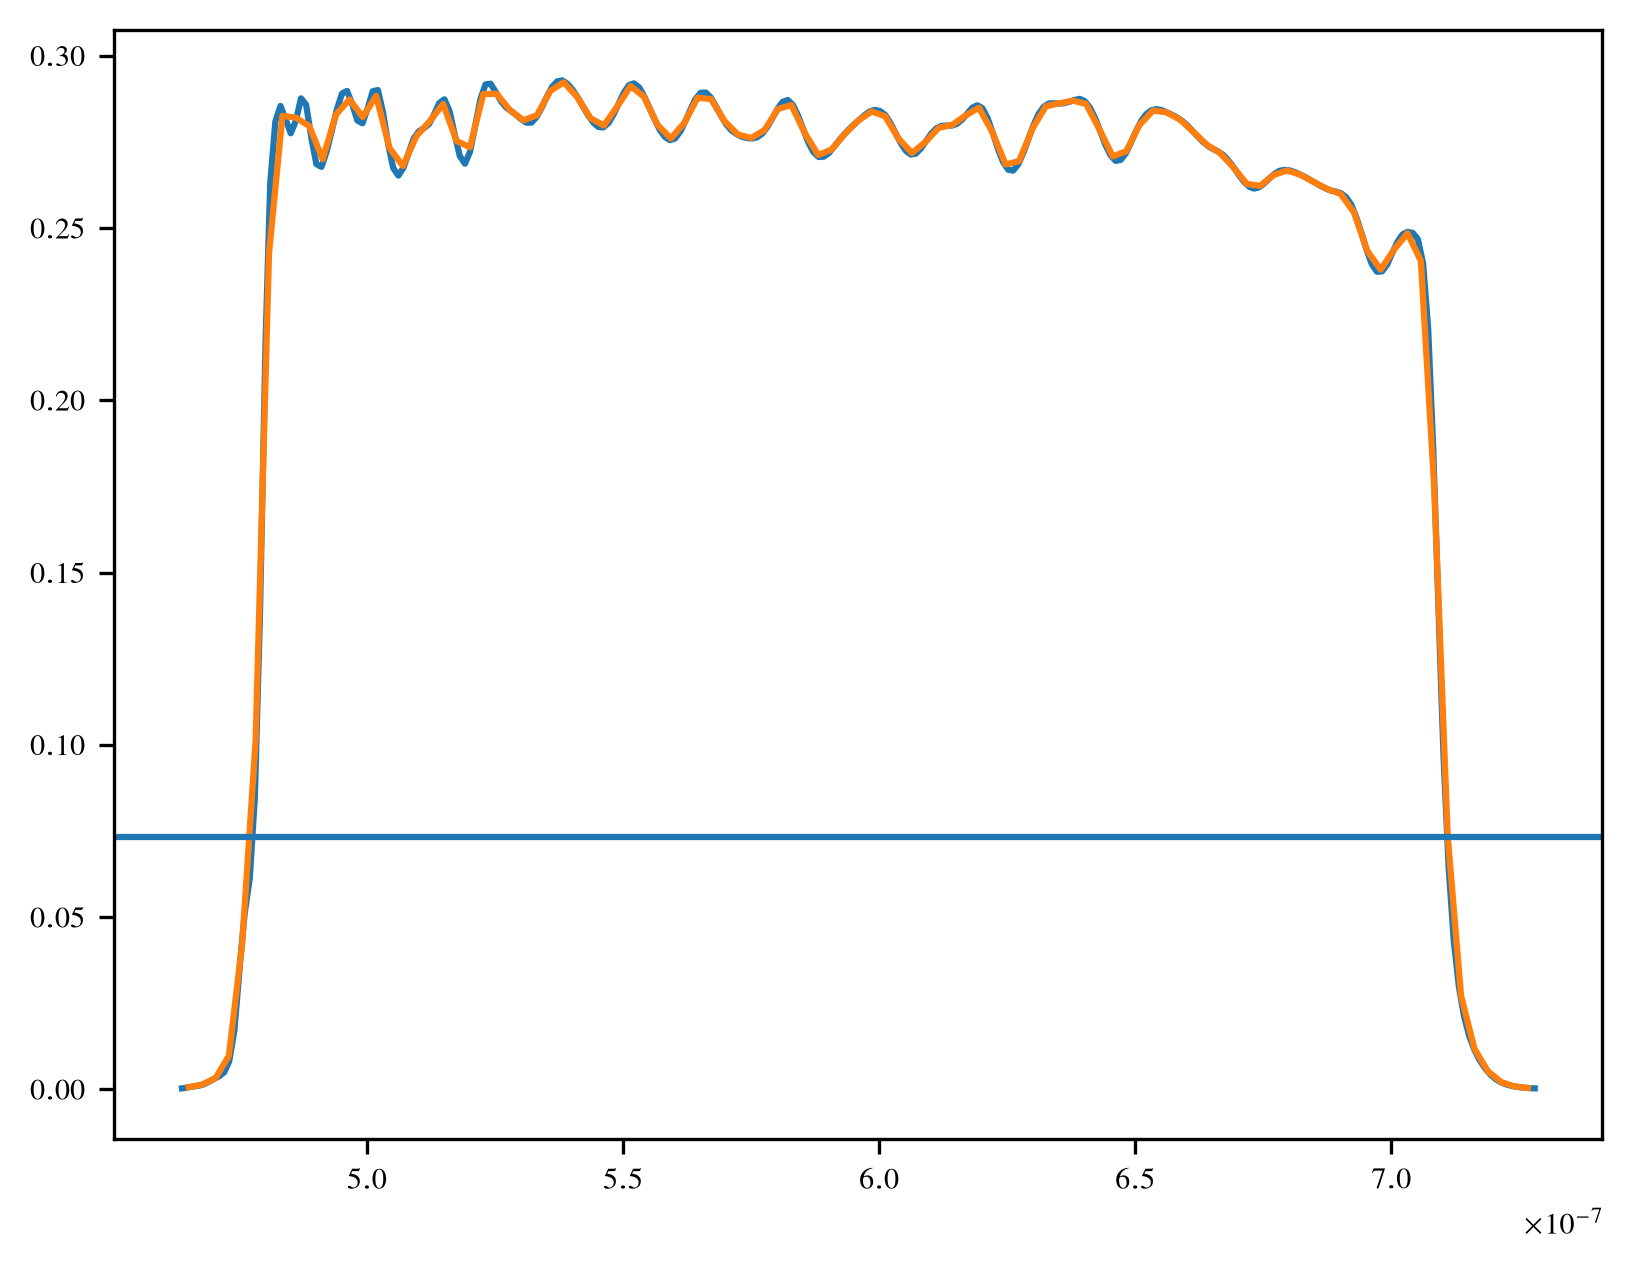

In [38]:
plt.plot(waves_trim, throughput_trim)
plt.plot(waves_bin, throughput_bin)
plt.axhline(0.25*np.max(throughput_trim))
plt.show()

In [39]:
# constructing the source
N = throughput_bin.size
# throughput_bin = np.ones(N)

spectrum_model = CombinedBasisSpectrum(waves_bin, throughput_bin, np.ones(N), np.eye(N))

source_model = dl.PointSource(
    spectrum=spectrum_model
)

# for psfnpix = 512, need at least 1024 wfnpix
wf_npix = 256 # might as well do 512 or 256
psf_npix = 128 # might as well do 256 or 128...
diameter = 2.4
oversample = 4

optics = MemorySafeWFC3Optics(wf_npixels=wf_npix, psf_npixels=psf_npix, psf_pixel_scale=0.039, oversample=oversample)
optics_s = MemorySafeWFC3Optics(wf_npixels=wf_npix, psf_npixels=2, psf_pixel_scale=0.039, oversample=oversample)

detector = dl.LayeredDetector([
    (
        'downsample',
        dl.detector_layers.Downsample(kernel_size=oversample)
    )
])

instrument = dl.Telescope(optics, source_model, detector)

instrument_s = dl.Telescope(optics_s, source_model, detector)

key1, key2, key3 = jr.split(jr.PRNGKey(4), 3)

# generate a higher order spectrum
eigvecs_606w = np.load('eigvecs_606w.npy')
nmodes_inject = 20
injected_spectrum = np.ones(N) + np.dot(eigvecs_606w[:,1:(nmodes_inject)], jr.uniform(key1, (nmodes_inject-1,), minval=-1, maxval=1))

# maximum well depth: 63,000 e. 
flux = 1e6
injected_spectrum *= flux/N #

img_s = model_psf(injected_spectrum, instrument_s)

# getting the proper flux
flux_ratio = 63000/np.max(img_s)
injected_spectrum *= flux_ratio

img_full = model_psf(injected_spectrum, instrument)

img_poisson = jr.poisson(key2, img_full)

read_noise = 3.0 # photoelectrons

data = img_poisson + read_noise*jr.normal(key3, img_poisson.shape)

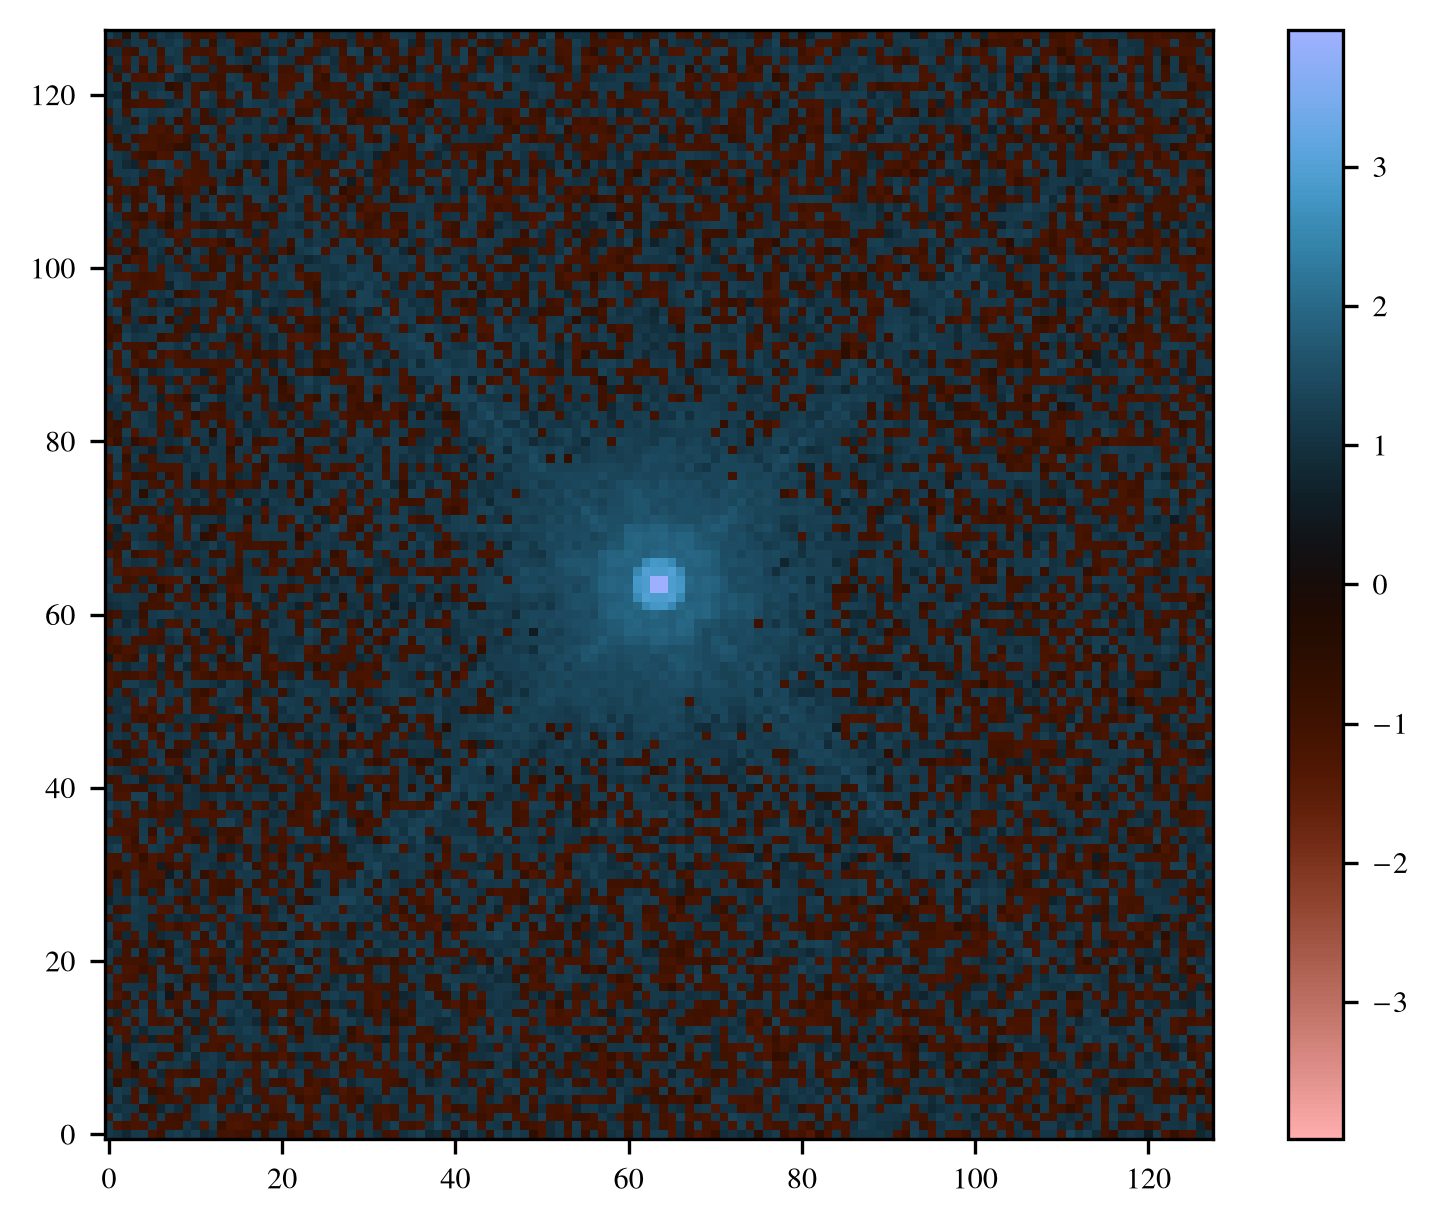

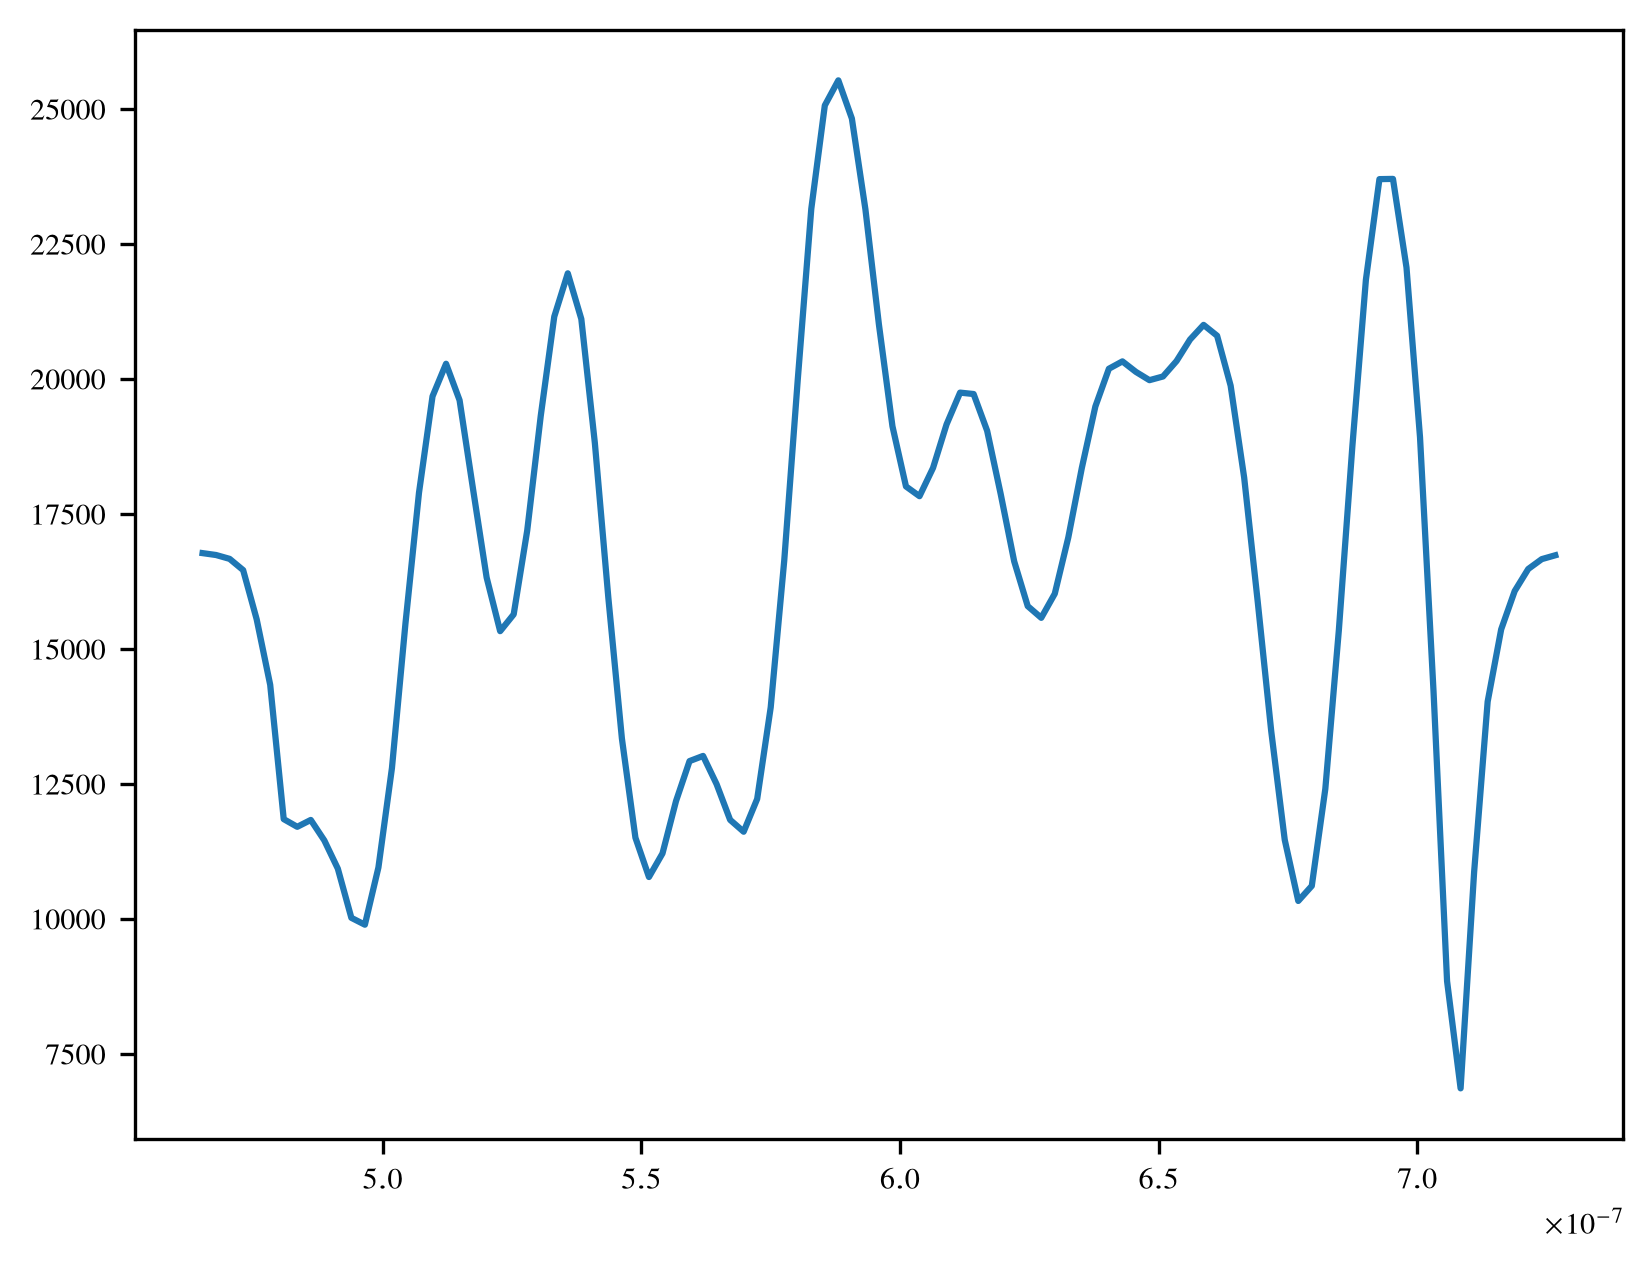

In [40]:
data_plot = np.sign(data)*np.abs(data)**(0.125)
v = np.max(np.abs(data_plot))
plt.imshow(data_plot, cmap='berlin_r', vmin=-v,vmax=v)
plt.colorbar()
plt.show()

plt.plot(waves_bin,injected_spectrum)

plt.show()
# sweet

In [41]:
# now time to recover.
from zodiax.diffops import hessian
import jax.scipy as jsp

def loss_fn(params, model, data):
    spectrum = params['spectrum']
    img = model_psf(spectrum, model)
    loss = -normal_logpdf(data, img, np.sqrt(np.maximum(data, 0) + read_noise**2)).sum()
    return loss

# do flat spectrum injection
injected_spectrum_model = (np.ones(N)/np.sum(throughput_bin)) * np.sum(data) # now do this because normalised by throughput

params = {
    "spectrum": injected_spectrum_model
}

# let us do preconditioning with the data... this is fine because we are somewhat close to maximum likelihood
# since we can just do a flat spectrum with the same total flux

# upon later consideration.. don't do wrt. data because you get strange eigval trends

# upon even later consideration... DO do wrt. data. trust.
f = lambda params: loss_fn(params, instrument, data)

H, unflatten = hessian(f, params)

H = 0.5 * (H + H.T) # symmetretise

In [42]:
# project my injected initial guess flat spectrum onto an orthogonal basis:
# Now take appropriate eigvecs and vals
eigvals, eigvecs = np.linalg.eigh(H)

idx = np.argsort(eigvals)[::-1]

eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

# Optional sign convention
for i in range(eigvecs.shape[0]):
    eigvecs = eigvecs.at[:, i].mul(np.sign(np.mean(eigvecs[5:6, i])))

a = eigvecs.T @ injected_spectrum_model

nbasis_fit = 12

spectrum_bins_fit = CombinedBasisSpectrum(waves_bin, throughput_bin, a[:nbasis_fit], eigvecs[:,:nbasis_fit])

source_fit = dl.PointSource(
    spectrum=spectrum_bins_fit
)

model_fit = dl.Telescope(optics, source_fit, detector)

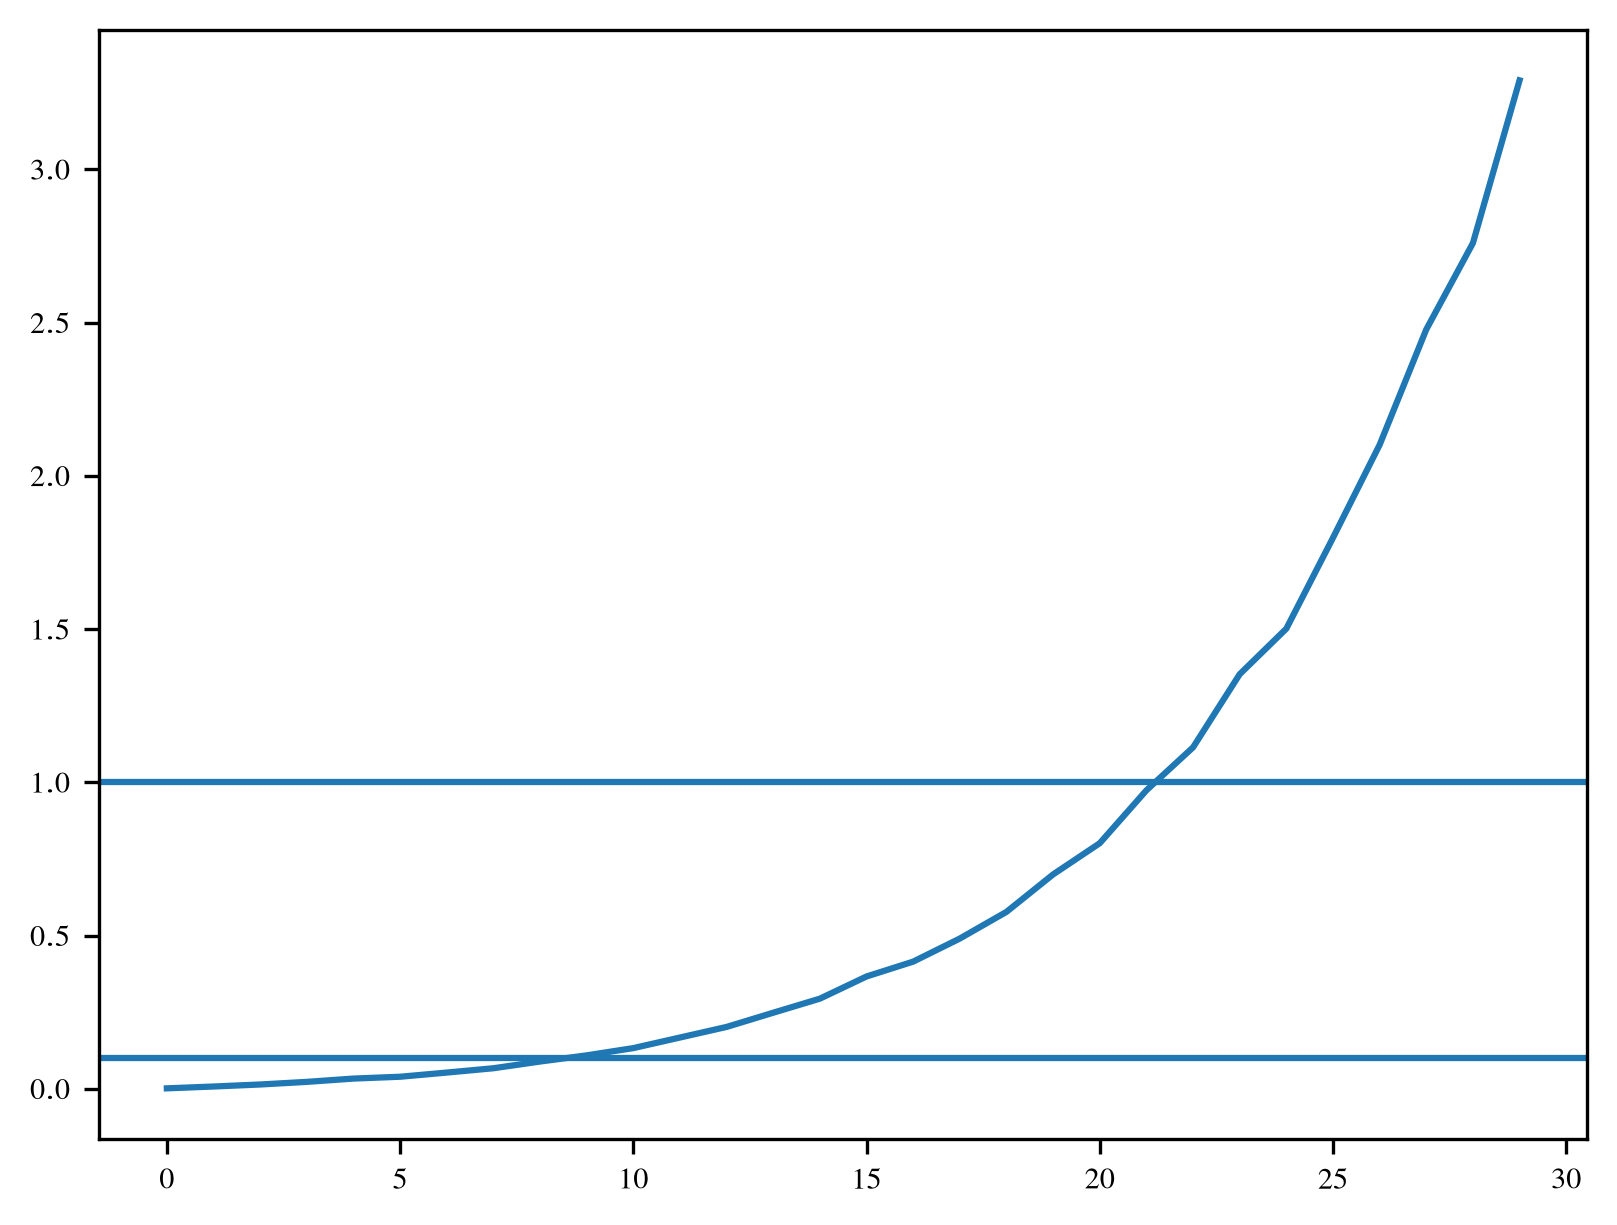

In [43]:
relstd = 1 / (np.abs(a[0]) * np.sqrt(eigvals))
plt.plot(relstd[:30])
plt.axhline(1.0)
plt.axhline(0.1)
plt.show()

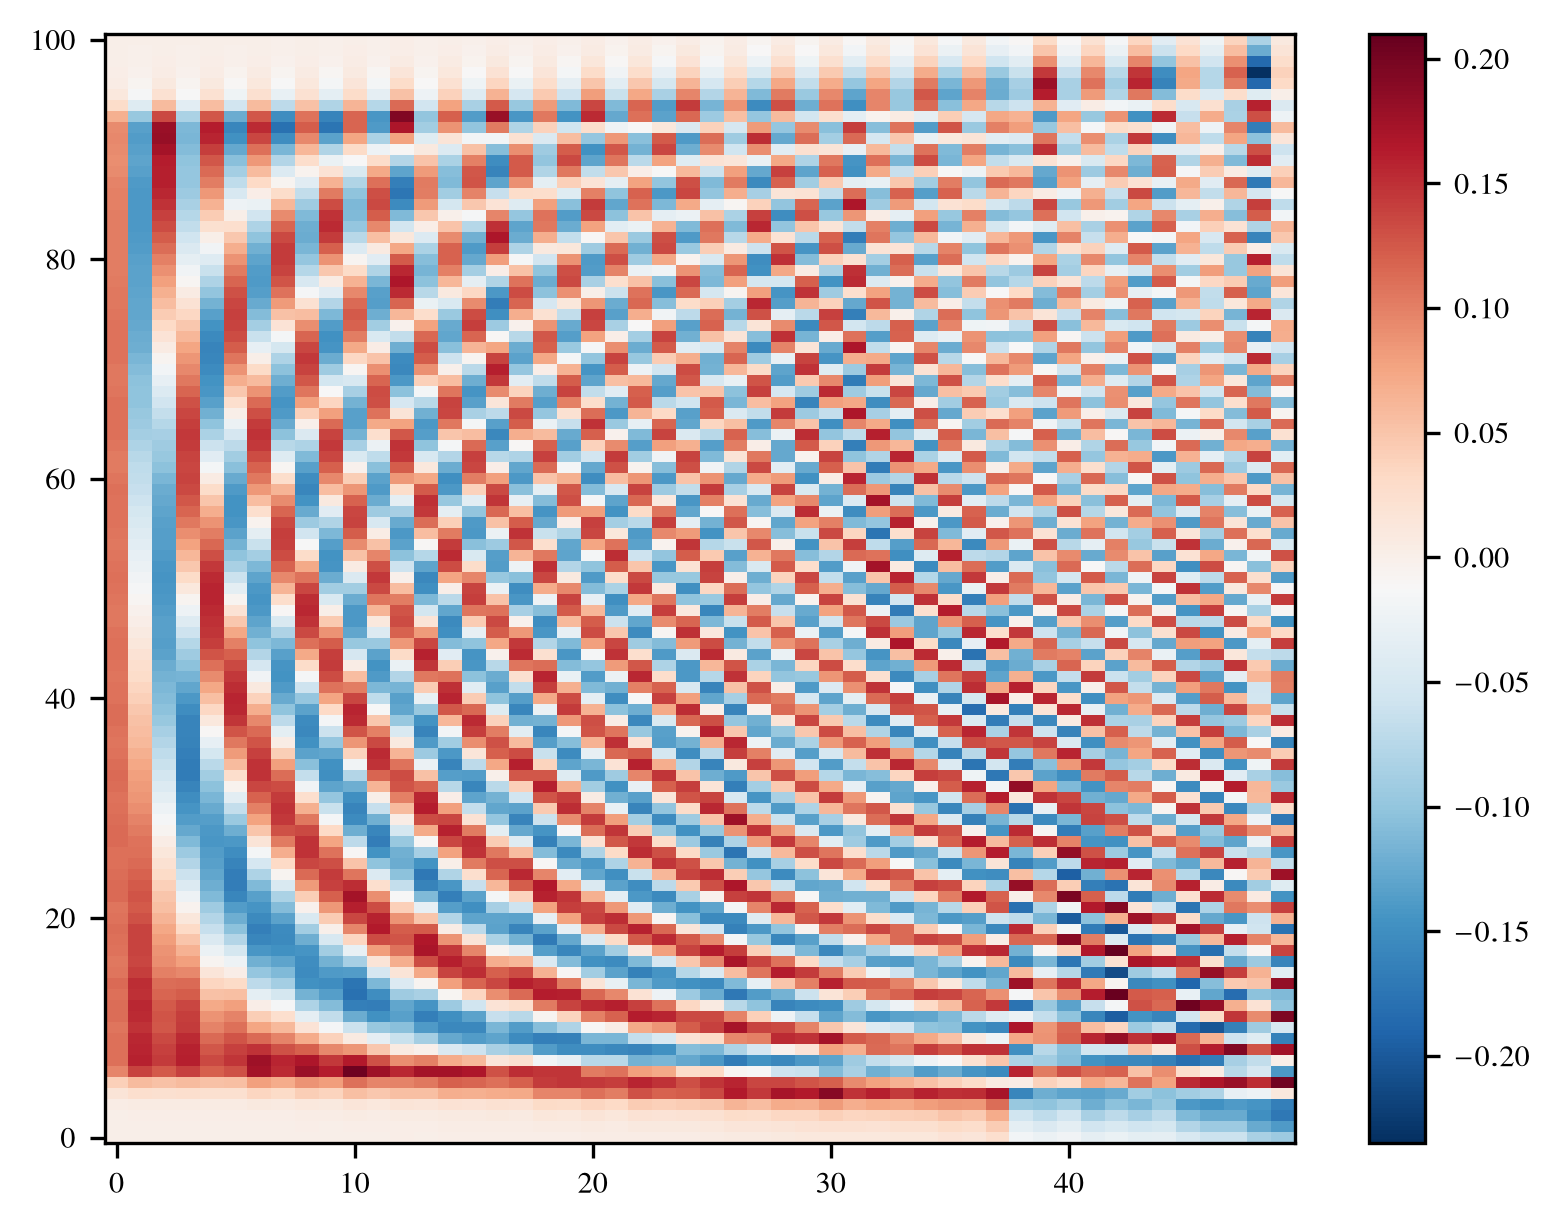

In [44]:
plt.imshow(eigvecs[:,:50], cmap='RdBu_r', aspect='auto')
plt.colorbar()
plt.show()

In [45]:
import equinox as eqx
import optax
from zodiax import optimisation as opt
from tqdm import tqdm
from jax.flatten_util import ravel_pytree
import jax.numpy as np

# JIT and grad transform the loss function
loss_grad_fn = eqx.filter_jit(eqx.filter_value_and_grad(loss_fn))

params = {'spectrum': a[:nbasis_fit]}

optimisers = {'spectrum': optax.sgd(1e-1)}

# Now we map the optimisers to the parameters and get the initial state
optim, state = opt.map_optimisers(params, optimisers)

# for natural gradient descent, use the covariance matrix
# in our case, just the inverse of the eigvals
C = np.diag(1/eigvals[:nbasis_fit])
# but some have too high covariance and break everything
# so do npmin with 1e14 (heuristic)

# Now we can run a simple optimisation loop
losses = []
params_out = []
pbar = tqdm(range(100))
for step in pbar:
    loss, grads = loss_grad_fn(params, model_fit, data)

    # precondition updates with the covariance matrix
    G, unflatten = ravel_pytree(grads)

    grads = unflatten(np.dot(G, C))
    
    # continue the gradient descent
    updates, state = optim.update(grads, state)
    params = optax.apply_updates(params, updates)
    pbar.set_postfix(log_loss=f"{np.log10(loss):.4f}")
    losses.append(loss)
    params_out.append(params)

losses = np.array(losses)

100%|██████████| 100/100 [00:29<00:00,  3.40it/s, log_loss=4.6257]


26.93558049171701


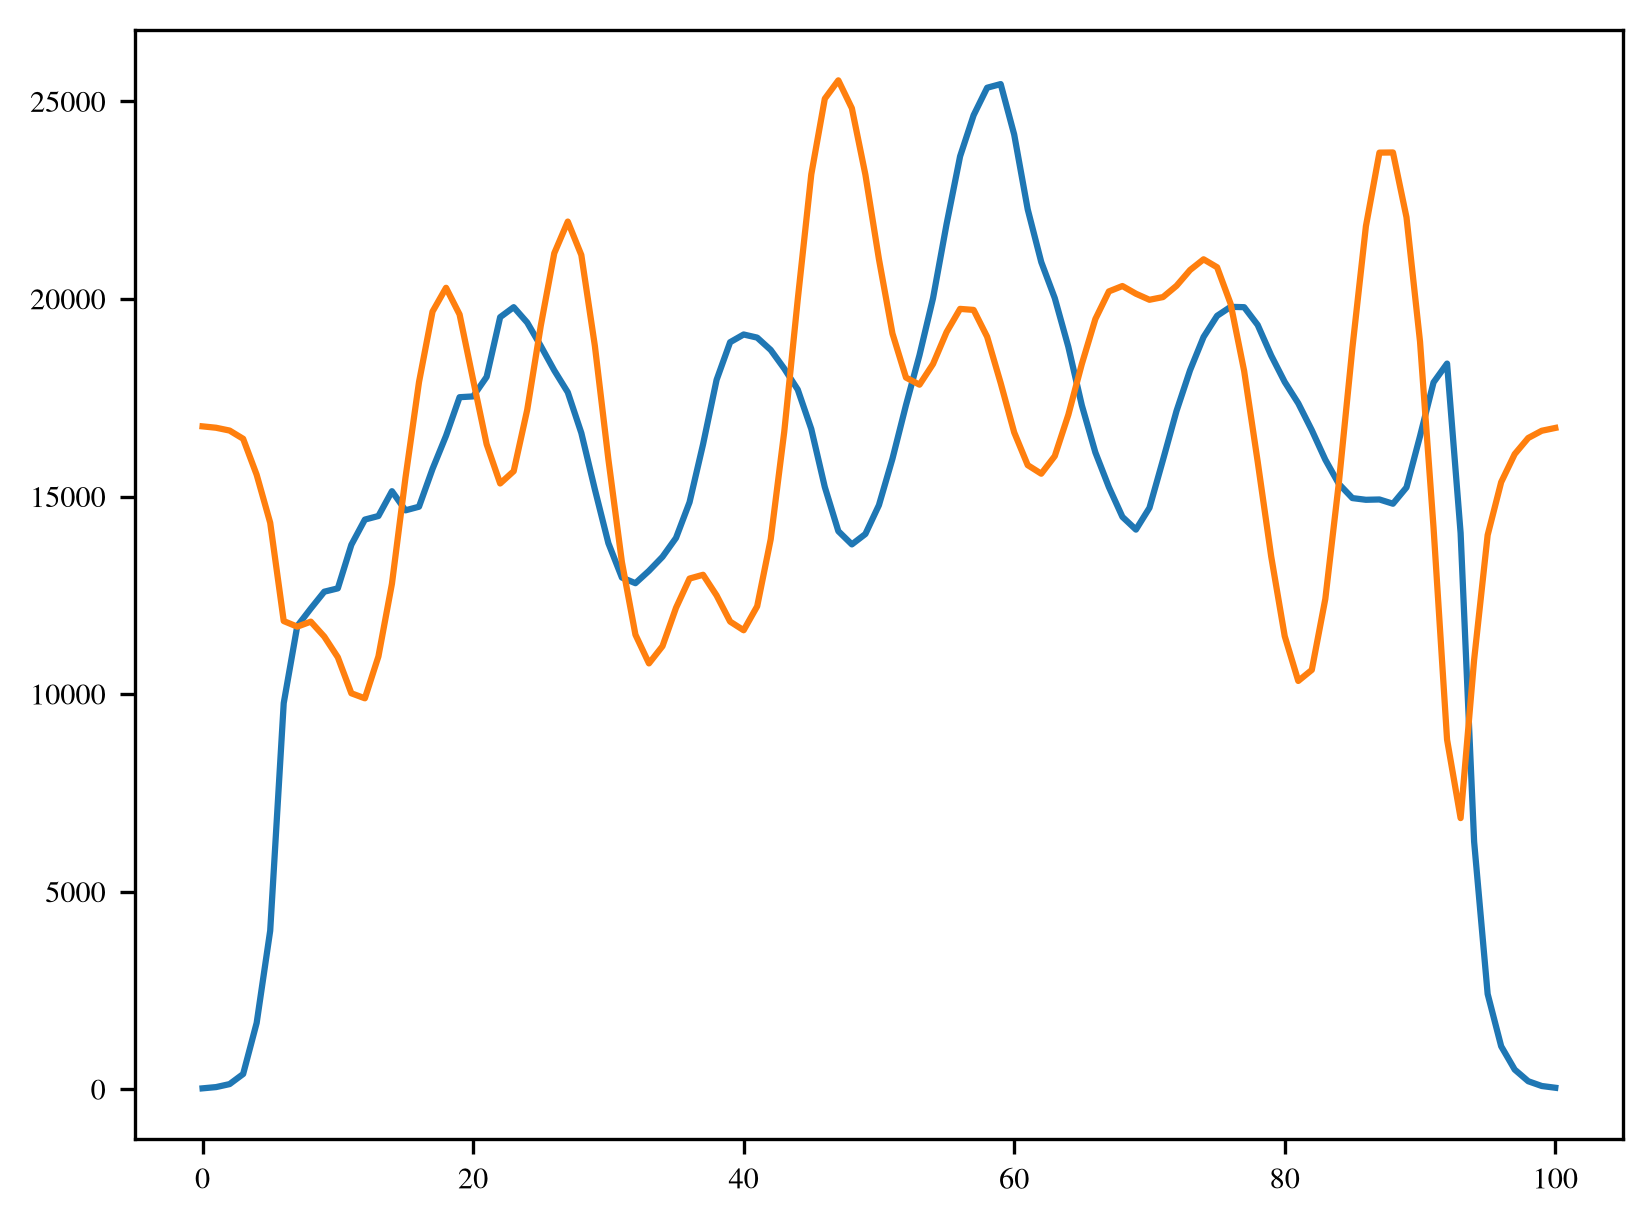

In [46]:
spectrum_new = eigvecs[:,:nbasis_fit] @ params_out[-1]['spectrum']
print(np.min(spectrum_new))
plt.plot(spectrum_new)
plt.plot(injected_spectrum)
plt.show()

In [47]:
params_new = {
    'spectrum':
    spectrum_new
}

# get the observed information
f_new = lambda params: loss_fn(params, instrument, data)

H_new, unflatten_new = hessian(f_new, params_new)

# construct new basis from observed information
eigvals_new, eigvecs_new = np.linalg.eigh(H_new)

idx_new = np.argsort(eigvals_new)[::-1]

eigvals_new = eigvals_new[idx_new]
eigvecs_new = eigvecs_new[:, idx_new]

for i in range(eigvecs_new.shape[0]):
    eigvecs_new = eigvecs_new.at[:, i].mul(np.sign(np.mean(eigvecs_new[5:6, i])))

a_new = eigvecs_new.T @ spectrum_new

In [48]:
nbasis_fit_2 = 12

spectrum_bins_fit_2 = CombinedBasisSpectrum(waves_bin, throughput_bin, a_new[:nbasis_fit_2], eigvecs_new[:,:nbasis_fit_2])

source_fit_2 = dl.PointSource(
    spectrum=spectrum_bins_fit_2
)

model_fit_2 = dl.Telescope(optics, source_fit_2, detector)

C_new = np.diag(1/eigvals_new[:nbasis_fit_2])

In [49]:
# do bfgs on the increased number of basis vecs
import optimistix as optx

args = (model_fit_2, data)

# reference point: this should become zero in scaled space
params_ref = {
    "spectrum": a_new[:nbasis_fit_2]
}

# usually use standard deviations, not variances
# abs because some negative
scale = np.sqrt(np.diag(np.abs(C_new)))

def to_scaled(params):
    return {
        "spectrum": (params["spectrum"] - params_ref["spectrum"]) / scale
    }

def from_scaled(params_scaled):
    return {
        "spectrum": params_ref["spectrum"] + params_scaled["spectrum"] * scale
    }

params0_scaled = to_scaled(params_ref)

def loss_fn_optx(params, args):
    model, data = args
    spectrum = params['spectrum']
    img = model_psf(spectrum, model)
    loss = -normal_logpdf(data, img, np.sqrt(np.maximum(data, 0) + read_noise**2)).sum()
    return loss

def loss_fn_optx_scaled(params_scaled, args):
    params = from_scaled(params_scaled)
    return loss_fn_optx(params, args)

solver = optx.BFGS(
    rtol=1e-10,
    atol=0.0,
    #norm=optx.rms_norm,
    verbose=False,
)

sol = optx.minimise(
    loss_fn_optx_scaled,
    solver,
    params0_scaled,
    args,
    max_steps=2048,
    throw=False,
)

params_final = from_scaled(sol.value)

print("result:", sol.result)
print("stats:", sol.stats)
print("start log loss:", np.log10(loss_fn_optx(params_ref, args)))
print("final log loss:", np.log10(loss_fn_optx(from_scaled(sol.value), args)))

# 4.6287903826883925
# 4.628799938107173

result: optimistix._solution.RESULTS<>
stats: {'max_steps': 2048, 'num_steps': Array(34, dtype=int64, weak_type=True)}
start log loss: 4.625683273180114
final log loss: 4.625683273179716


26.934946132976485


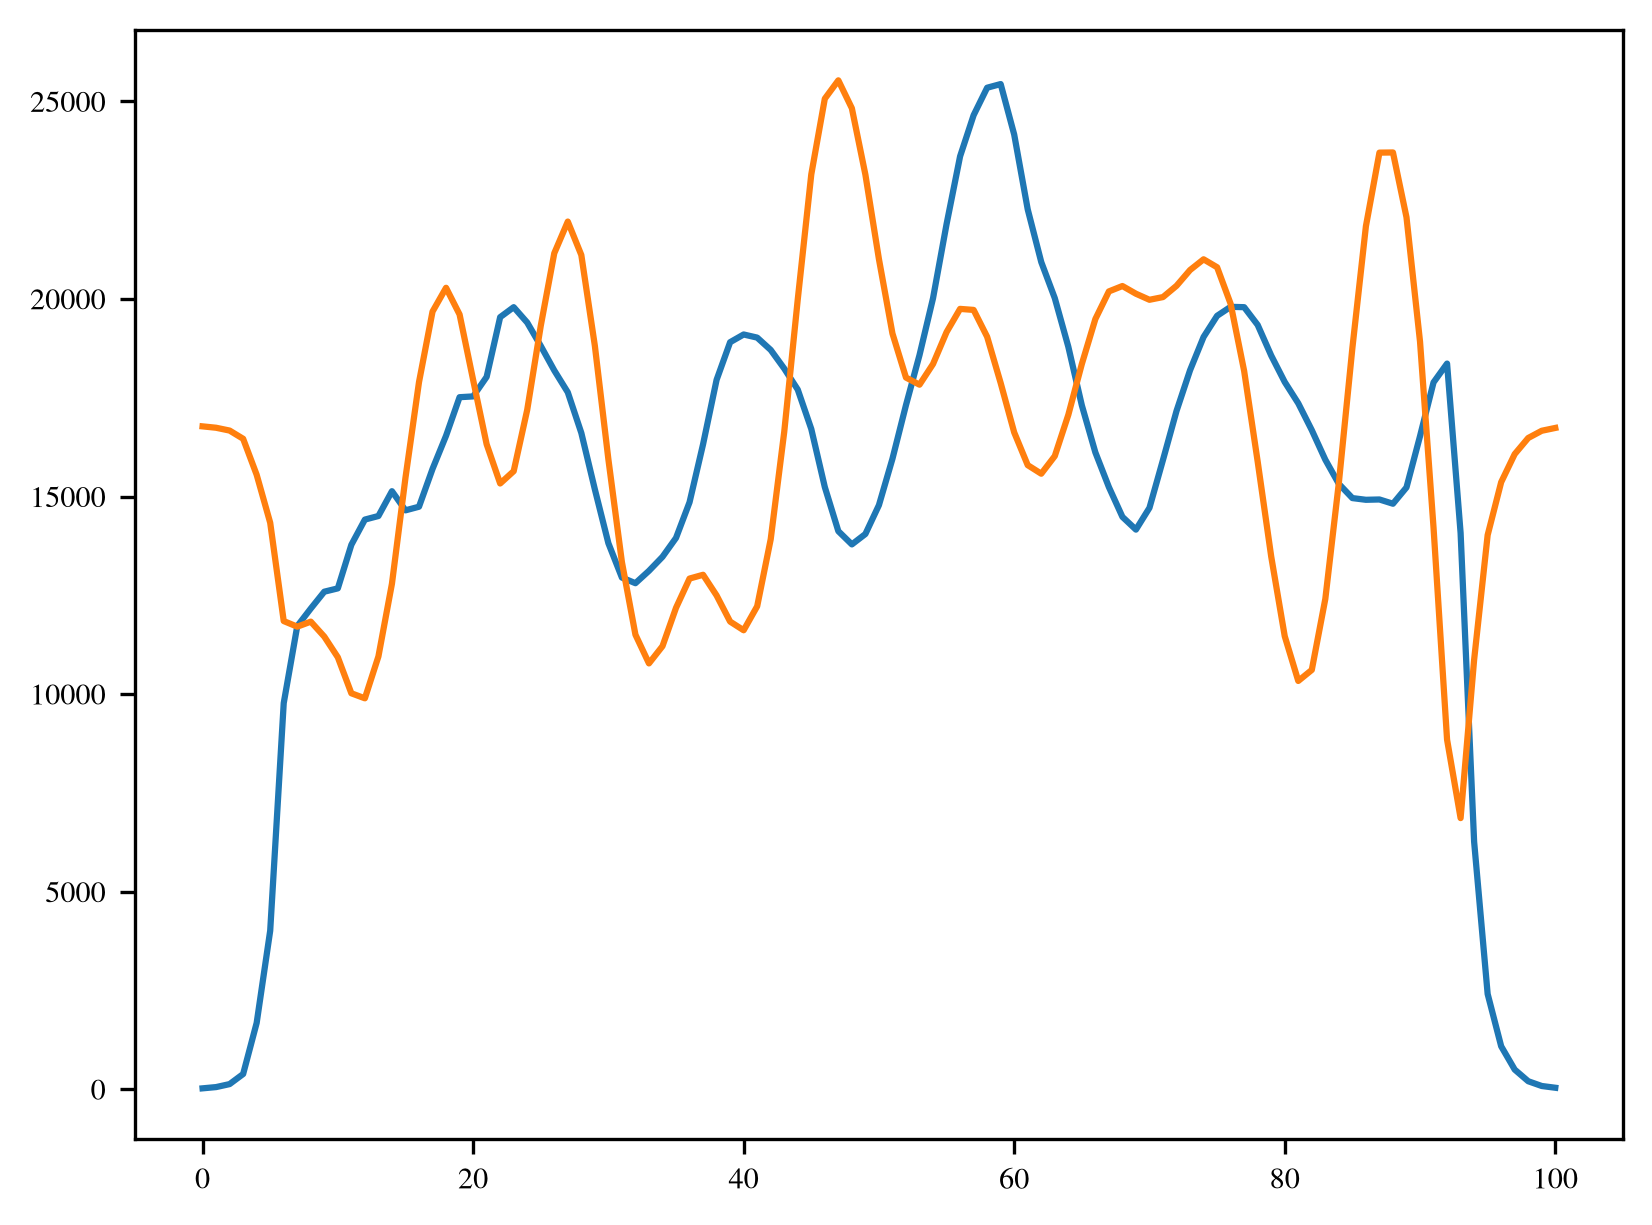

In [50]:
spectrum_found = eigvecs_new[:,:nbasis_fit_2] @ params_final['spectrum']
print(spectrum_found[np.argmin(spectrum_found)])
plt.plot(spectrum_found)
plt.plot(injected_spectrum)
plt.show()

In [51]:
# spectrum_found = eigvecs_new[:,:nbasis_fit_2] @ params_final['spectrum']

params_found = {
    'spectrum':
    spectrum_found
}

# get the observed information
f_found = lambda params: loss_fn(params, instrument, data)

H_found, unflatten_found = hessian(f_found, params_found)

In [52]:
# construct new basis from observed information
eigvals_found, eigvecs_found = np.linalg.eigh(H_found)

idx_found = np.argsort(eigvals_found)[::-1]

eigvals_found = eigvals_found[idx_found]
eigvecs_found = eigvecs_found[:, idx_found]

for i in range(eigvecs_found.shape[0]):
    eigvecs_found = eigvecs_found.at[:, i].mul(np.sign(np.mean(eigvecs_found[5:6, i])))

a_found = eigvecs_found.T @ spectrum_found

coeffs_inject = np.linalg.solve(eigvecs_found, injected_spectrum)

cov_found = np.diag(1/eigvals_found) # this is kinda sus but I think its correct

nmodes_out = 8
spec_var = (eigvecs_found[:,:nmodes_out]**2) @ np.diag(cov_found[:nmodes_out, :nmodes_out])

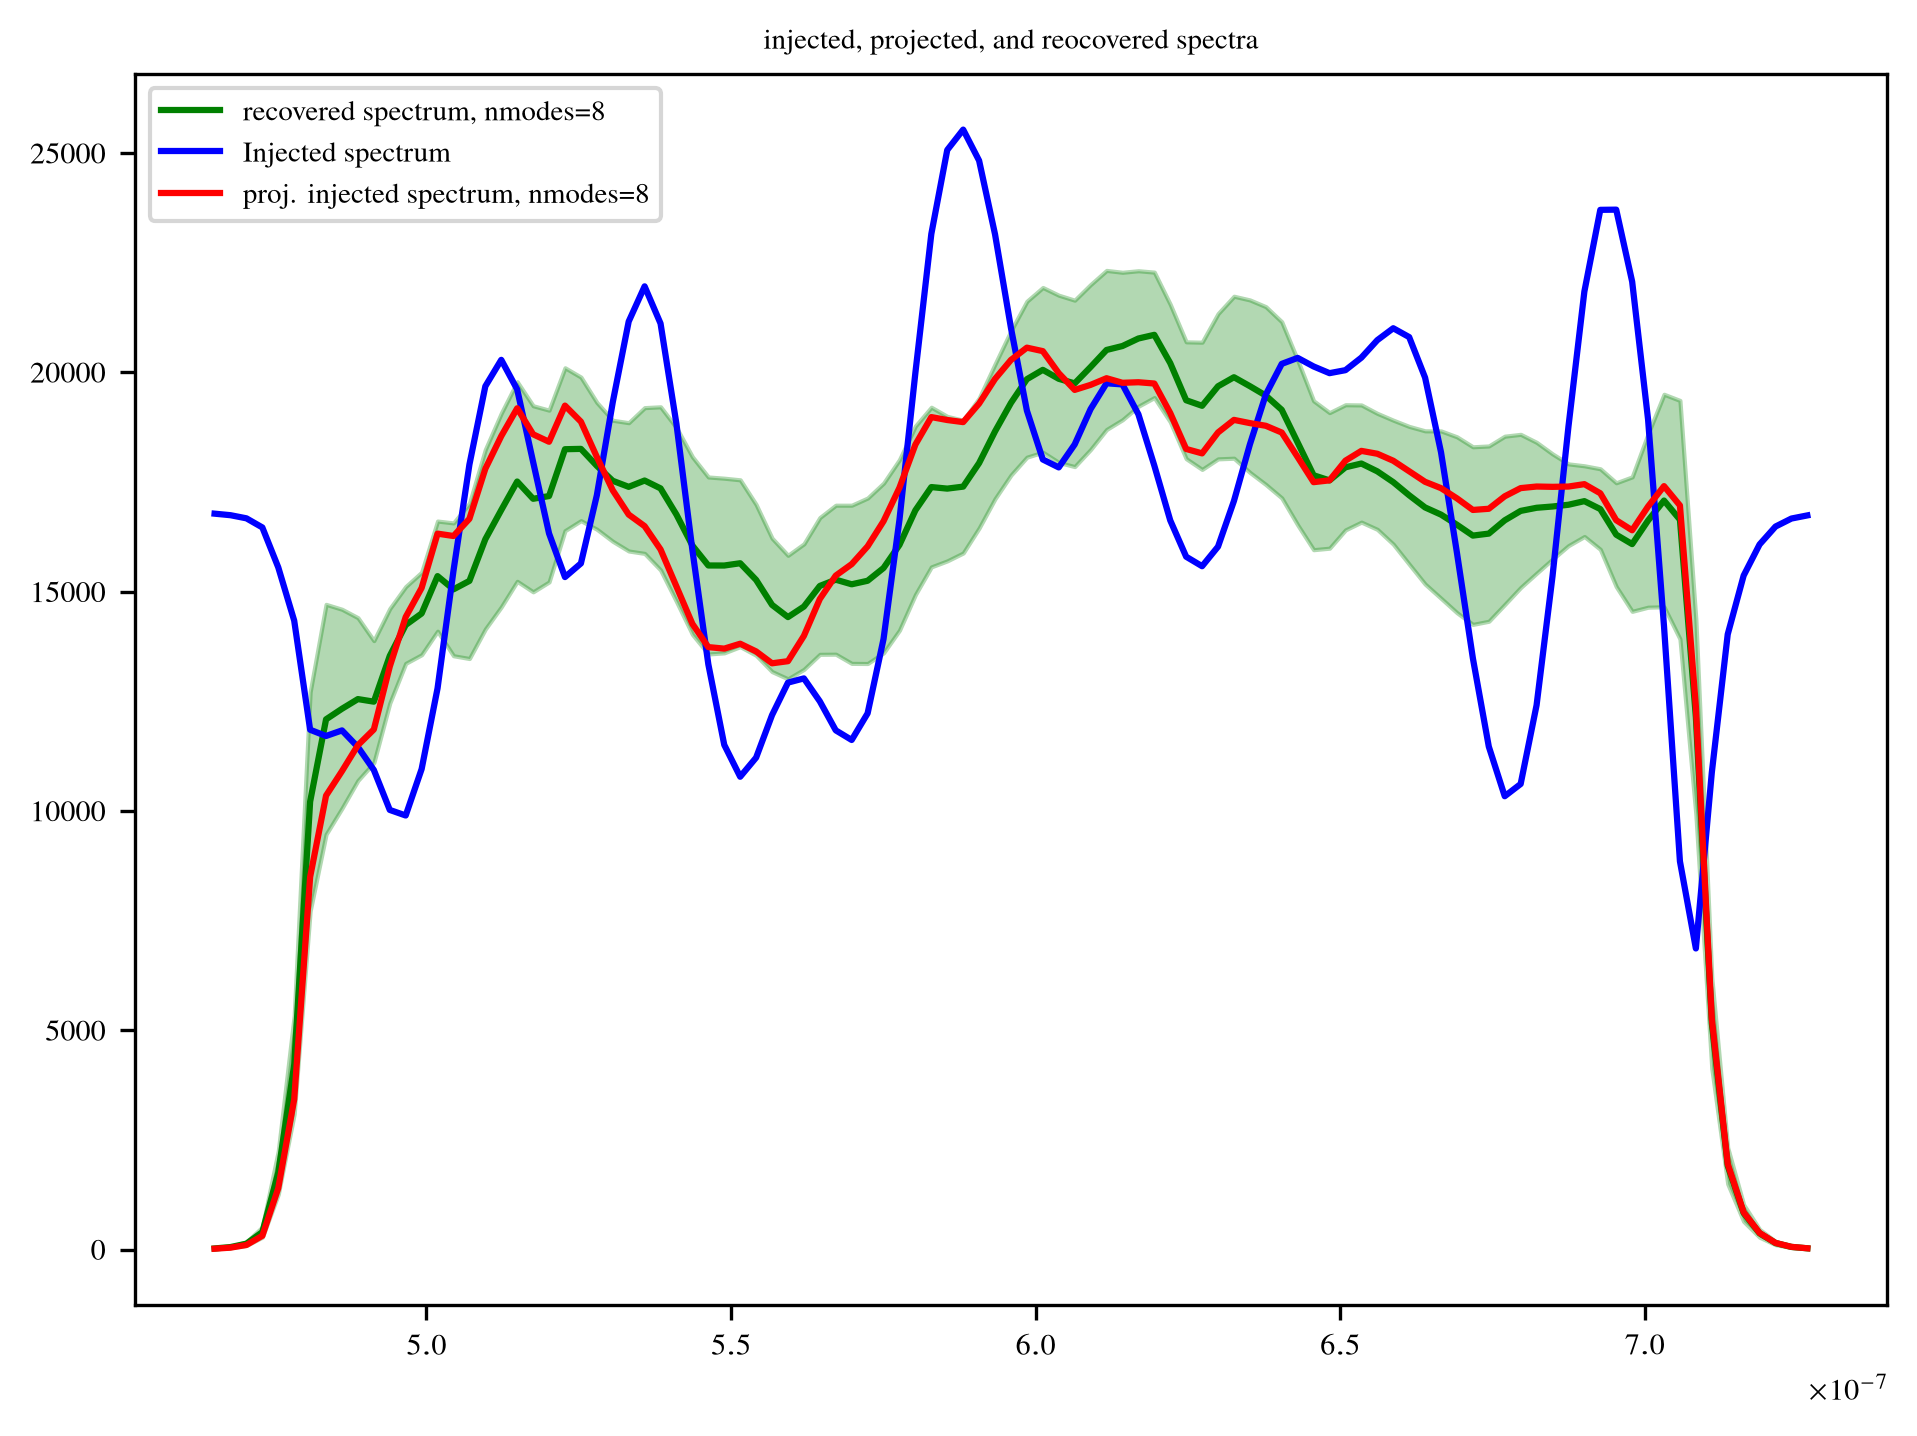

In [53]:
# plt.figure(figsize=(12,6))
plt.subplot(1,1,1)
plt.title('injected, projected, and reocovered spectra')

spec_mean = eigvecs_found[:,:nmodes_out] @ a_found[:nmodes_out]
spec_std = np.sqrt(spec_var)

plt.plot(
    waves_bin,
    spec_mean,
    color='green',
    label=f'recovered spectrum, nmodes={nmodes_out}'
)

plt.fill_between(
    waves_bin,
    spec_mean - spec_std,
    spec_mean + spec_std,
    color='green',
    alpha=0.3
)

plt.plot(waves_bin, injected_spectrum, color='blue', label='Injected spectrum')
plt.plot(waves_bin, eigvecs_found[:,:nmodes_out] @ coeffs_inject[:nmodes_out], color='red', label=f'proj. injected spectrum, nmodes={nmodes_out}')
# plt.plot(waves_bin, bandpass*np.max(injected_spectrum)/np.max(bandpass), ls='--', color='orange')
plt.legend()

# plt.subplot(1,2,2)
# plt.title('residual z-scores of projected v. recovered spectra')
# spectrum_zs = (eigvecs_new[:,:nmodes_out]@coeffs_inject[:nmodes_out] - eigvecs_new[:,:nmodes_out] @ coeffs_recov[:nmodes_out]) / ((1e0)*(np.sqrt((spec_var)))) 
# plt.hist(spectrum_zs, bins=20, density=True)
# zs = np.linspace(-5,5,1000)
# plt.plot(zs, np.exp(-zs**2/2)/np.sqrt(2*np.pi))

# plt.ylim(0,6500)
plt.tight_layout()
plt.show() 
# this looks like the strat.


In [54]:
# binning the output to the correct number of modes and propagating uncertainties....
# retained info ~ actual info
fisher_cdf = np.cumsum(np.diag(H_found))/np.sum(np.diag(H_found))

wave = np.asarray(waves_bin)
n_bins = nmodes_out

# Native cell edges from wavelength centres
native_edges = np.empty(len(wave) + 1)
native_edges = native_edges.at[1:-1].set(
    0.5 * (wave[:-1] + wave[1:])
)
native_edges = native_edges.at[0].set(
    wave[0] - 0.5 * (wave[1] - wave[0])
)
native_edges = native_edges.at[-1].set(
    wave[-1] + 0.5 * (wave[-1] - wave[-2])
)

In [55]:
import jax
import jax.numpy as np
import numpy as onp
from scipy.optimize import minimize

# Retained modal projector
Q_N = eigvecs_found[:, :nmodes_out]
P = Q_N @ Q_N.T

wave = np.asarray(waves_bin)
native_widths = np.diff(native_edges)

wave_min = wave[0]
wave_max = wave[-1]
full_span = wave_max - wave_min

# Maximum permitted inward displacement of either outer edge
max_edge_shift = 0.1 * full_span

In [56]:
def construct_B_from_edges(wave_lo, wave_hi):
    """Construct equal-width top-hat bins between two wavelength cutoffs."""

    target_edges = np.linspace(
        wave_lo,
        wave_hi,
        n_bins + 1,
    )

    target_centres = 0.5 * (
        target_edges[:-1] + target_edges[1:]
    )

    target_widths = np.diff(target_edges)

    # Shape: (n_bins, n_native_wavelengths)
    overlap_left = np.maximum(
        target_edges[:-1, None],
        native_edges[:-1][None, :],
    )

    overlap_right = np.minimum(
        target_edges[1:, None],
        native_edges[1:][None, :],
    )

    overlap = np.maximum(
        0.0,
        overlap_right - overlap_left,
    )

    # Code convention: rows are bins
    B = overlap / native_widths[None, :]

    return B, target_edges, target_centres, target_widths

In [57]:
@jax.jit
def edge_objective(edges):
    wave_lo, wave_hi = edges

    B, _, _, _ = construct_B_from_edges(
        wave_lo,
        wave_hi,
    )

    projected_B = B @ P

    return (
        np.sum((projected_B - B)**2)
        / np.sum(B**2)
    )

In [58]:
objective_jit = jax.jit(edge_objective)

initial_edges = onp.array([
    float(wave_min),
    float(wave_max),
])

bounds = [
    (
        float(wave_min),
        float(wave_min + max_edge_shift),
    ),
    (
        float(wave_max - max_edge_shift),
        float(wave_max),
    ),
]

result = minimize(
    lambda x: float(
        objective_jit(np.asarray(x))
    ),
    x0=initial_edges,
    method="Powell",
    bounds=bounds,
    options={
        "xtol": 1e-12,
        "ftol": 1e-12,
        "maxiter": 1000,
    },
)

wave_lo_opt, wave_hi_opt = result.x

B, target_edges, target_centres, target_widths = (
    construct_B_from_edges(
        np.asarray(wave_lo_opt),
        np.asarray(wave_hi_opt),
    )
)

K = B @ P

print(
    f"Lower cutoff: {wave_lo_opt * 1e10:.3f} Angstrom"
)
print(
    f"Upper cutoff: {wave_hi_opt * 1e10:.3f} Angstrom"
)
print(
    f"Retained wavelength span: "
    f"{(wave_hi_opt - wave_lo_opt) / float(full_span):.4%}"
)
print(
    f"Relative squared projection error: "
    f"{result.fun:.6e}"
)

Lower cutoff: 4749.461 Angstrom
Upper cutoff: 7117.335 Angstrom
Retained wavelength span: 90.5548%
Relative squared projection error: 1.643715e-01


In [59]:
# Range of actual lower and upper wavelength edges explored
n_grid = 150

wave_lo_grid = np.linspace(
    wave_min,
    wave_min + max_edge_shift,
    n_grid,
)

wave_hi_grid = np.linspace(
    wave_max - max_edge_shift,
    wave_max,
    n_grid,
)

# Evaluate edge_objective([wave_lo, wave_hi]) over the 2D grid
def objective_for_lower_edge(wave_lo):
    return jax.vmap(
        lambda wave_hi: edge_objective(
            np.array([wave_lo, wave_hi])
        )
    )(wave_hi_grid)

loss_grid = jax.vmap(
    objective_for_lower_edge
)(wave_lo_grid)

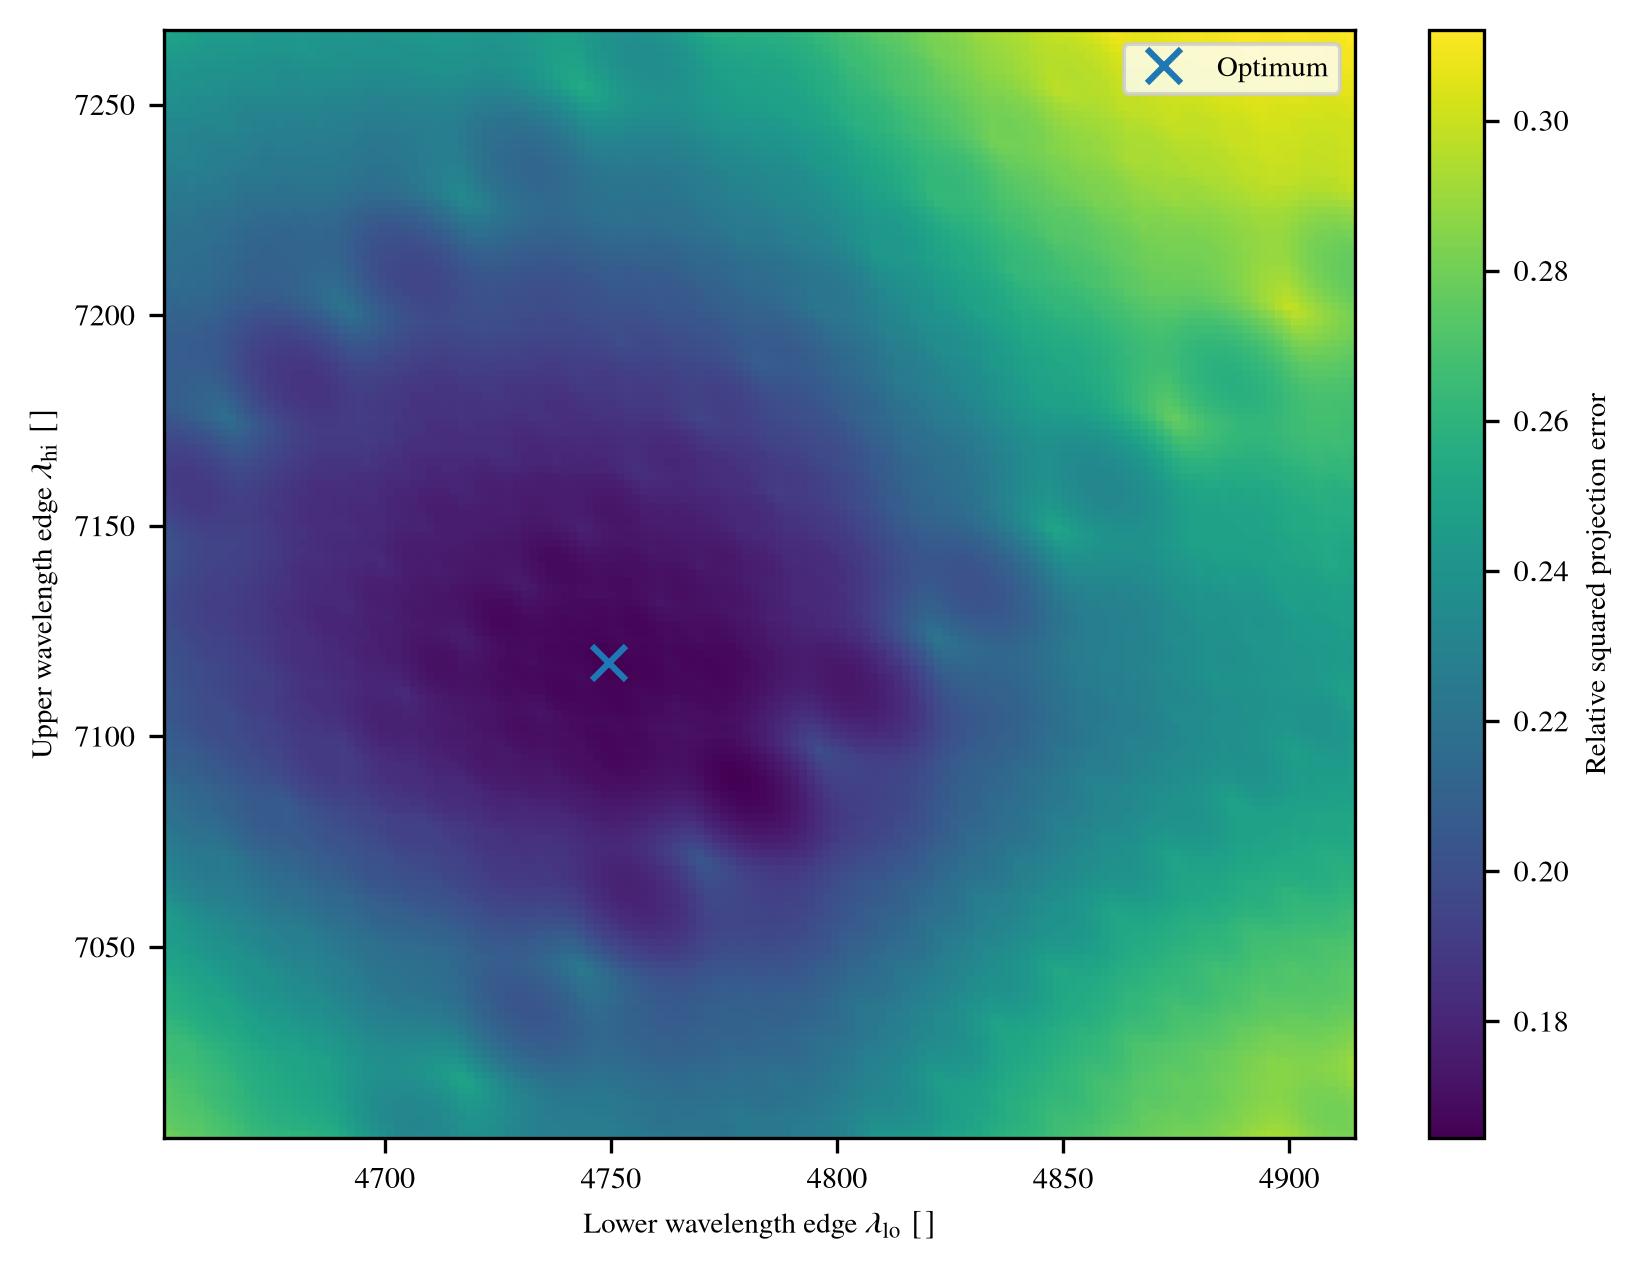

In [60]:
fig, ax = plt.subplots()

mesh = ax.pcolormesh(
    np.asarray(wave_lo_grid) * 1e10,
    np.asarray(wave_hi_grid) * 1e10,
    np.asarray(loss_grid).T,
    shading="auto",
)

ax.plot(
    wave_lo_opt * 1e10,
    wave_hi_opt * 1e10,
    "x",
    markersize=8,
    markeredgewidth=1.5,
    label="Optimum",
)

ax.set_xlabel(
    r"Lower wavelength edge $\lambda_{\rm lo}\ [\mathrm{\AA}]$"
)
ax.set_ylabel(
    r"Upper wavelength edge $\lambda_{\rm hi}\ [\mathrm{\AA}]$"
)

fig.colorbar(
    mesh,
    ax=ax,
    label="Relative squared projection error",
)

ax.legend()
plt.show()

In [61]:
# get far edges
# tail = 0.005 # 0.5% on each tail.
# tail = 0.000257
# # tail = 0.0018
# wave_lo = np.interp(tail, fisher_cdf, waves_bin)
# wave_hi = np.interp(1 - tail, fisher_cdf, waves_bin)
wave_lo = wave_lo_opt
wave_hi = wave_hi_opt

# construct edges, centres, widths
target_edges = np.linspace(wave_lo, wave_hi, n_bins + 1)
target_centres = 0.5 * (target_edges[:-1] + target_edges[1:])
target_widths = np.diff(target_edges)

# overlap matrix
B = np.zeros((n_bins, len(wave)))

for b in range(n_bins):
    for j in range(len(wave)):
        overlap = np.maximum(
            0.0,
            np.minimum(target_edges[b + 1], native_edges[j + 1])
            - np.maximum(target_edges[b], native_edges[j]),
        )

        B = B.at[b, j].set(overlap)

native_widths = np.diff(native_edges)

B = B / native_widths[None, :]

bin_flux = B @ spec_mean
# just define that
E = eigvecs_found[:, :nmodes_out] # uncomment if not doing the above thing

BE = B @ E

coarse_cov = BE @ cov_found[:nmodes_out, :nmodes_out] @ BE.T
coarse_sigma = np.sqrt(np.diag(coarse_cov))

bin_recov_flux_angstrom = bin_flux/target_widths * 1e-10
recov_flux_angstrom = spec_mean/native_widths * 1e-10
injec_flux_angstrom = injected_spectrum/native_widths * 1e-10

waves_angstrom = waves_bin * 1e10
bin_centres_angstrom = target_centres * 1e10
bin_widths_angstrom = target_widths * 1e10

coarse_sigma_angstrom = coarse_sigma/target_widths * 1e-10
recov_std_angstrom = spec_std/native_widths * 1e-10

projec_flux_angstrom = eigvecs_found[:,:nmodes_out] @ coeffs_inject[:nmodes_out]/native_widths * 1e-10

injected_bin_flux_angstrom = B @ injected_spectrum/target_widths * 1e-10

projected_bin_flux_angstrom = B @ eigvecs_found[:,:nmodes_out] @ coeffs_inject[:nmodes_out]/target_widths * 1e-10

# K = B @ E @ E.T # again uncomment if not doing the above cell

In [62]:
coarse_cov_angstrom = (
    coarse_cov
    / target_widths[:, None]
    / target_widths[None, :]
    * 1e-20
)

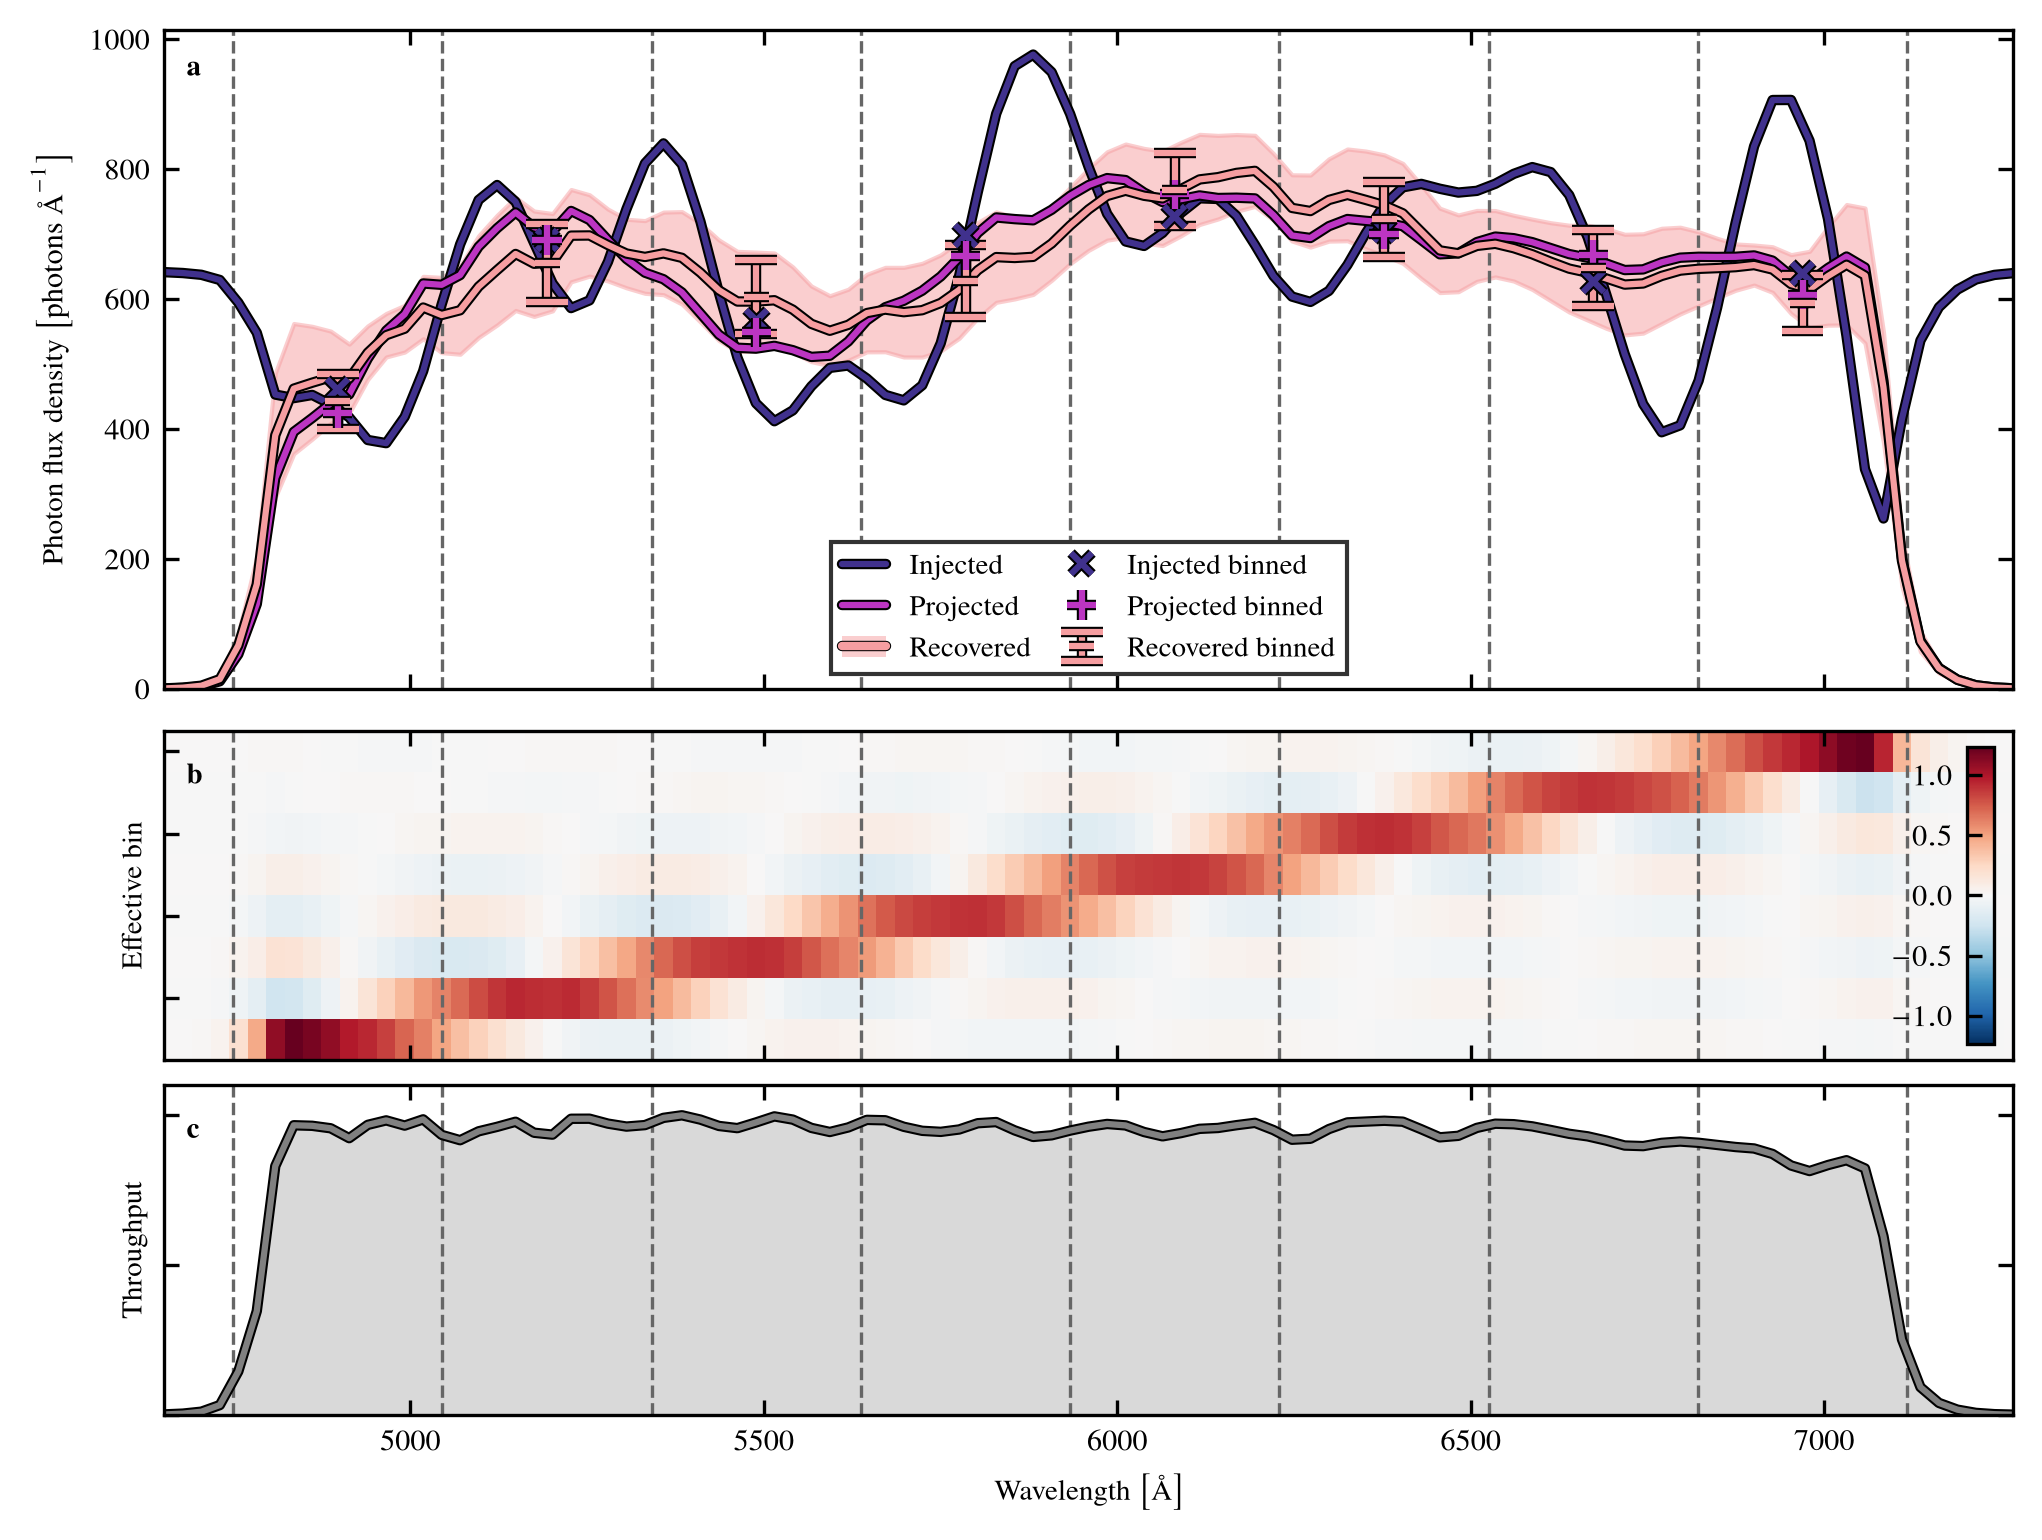

In [ ]:
import matplotlib.patheffects as pe

from cmap import Colormap
cmap = Colormap('bubblegum').to_mpl()
# cmap = plt.colormaps['plasma_r']

c_inj = cmap(0.2)
c_proj = cmap(0.55)
c_recov = cmap(0.9)

# c_inj = "0.1"
# c_proj = "0.5"
# c_recov = "0.9"

bar_colour = cmap(0.72)  # yellow-green

path_effects = [
    pe.Stroke(linewidth=2.5, foreground="k"),
    pe.Normal(),
]

fig, (ax, ax_K, ax_info) = plt.subplots(
    3, 1,
    figsize=(fig_width, 0.75 * fig_width),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1, 1]},
    constrained_layout=True,
)

# ax.bar(bin_centres_angstrom, bin_recov_flux_angstrom, width=bin_widths_angstrom, #path_effects=path_effects,
#        alpha=0.5,
#        edgecolor='k',
#        linewidth=1.2,
#        color=c_recov)

for edge in target_edges:
    ax.axvline(
        edge*1e10,
        color="0.4",
        linewidth=0.8,
        linestyle="--",
    )

ax.set_ylim(0,1015)

ax.plot(waves_angstrom, injec_flux_angstrom, color=c_inj, label=r'Injected',
        path_effects=path_effects,
        solid_capstyle='round',
        ls='-',
        )

ax.plot(waves_angstrom, projec_flux_angstrom, color=c_proj, label=r'Projected',
        path_effects=path_effects,
        ls='-',
        solid_capstyle='round')

recov_line = ax.plot(
    waves_angstrom,
    recov_flux_angstrom,
    color=c_recov,
    #label=r'Recovered',
    path_effects=path_effects,
    solid_capstyle='round',
    ls='-',
)

recov_fill = ax.fill_between(
    waves_angstrom,
    recov_flux_angstrom - recov_std_angstrom,
    recov_flux_angstrom + recov_std_angstrom,
    color=c_recov,
    alpha=0.5,
)

ax.errorbar(bin_centres_angstrom, bin_recov_flux_angstrom, yerr=coarse_sigma_angstrom, fmt="_", ecolor=c_recov, 
            capsize=5,
            elinewidth=1.5,
            capthick=1.5,
            path_effects=path_effects,
            label='Recovered binned',
            markerfacecolor='none',
            markeredgecolor=c_recov,
            markeredgewidth=1.5,)

ax.plot(
    bin_centres_angstrom,
    injected_bin_flux_angstrom,
    "x",
    color=c_inj,
    markersize=5,
    markeredgewidth=1.5,
    label=r"Injected binned",
    path_effects=path_effects
)

ax.plot(
    bin_centres_angstrom,
    projected_bin_flux_angstrom,
    "+",
    color=c_proj,
    markersize=7,
    markeredgewidth=1.5,
    label=r"Projected binned",
    path_effects=path_effects
)

ax.set_ylabel(r'Photon flux density $\big[\mathrm{photons}\  \text{\AA}^{-1}\big]$')

handles, labels = ax.get_legend_handles_labels()

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
recov_legend = (
    Patch(
        facecolor=c_recov,
        edgecolor="none",
        alpha=0.5,
    ),
    Line2D(
        [0], [0],
        color=c_recov,
        linewidth=2,
        path_effects=path_effects,
        solid_capstyle="round",
        ls='-'
    ),
)
handles.insert(2, recov_legend)
labels.insert(2, "Recovered")

ax.legend(handles, labels, 
          ncols=2, 
          columnspacing=1.0, 
          handlelength=1.5, 
          loc='lower center', 
          frameon=True, 
          framealpha=1,
          edgecolor='0.2', 
          fancybox=False)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
)

ax.text(
    0.012, 0.96,
    r'\textbf{a}',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k'
)

#
v = np.max(np.abs(K))
im = ax_K.imshow(
    K,
    origin="lower",
    aspect="auto",
    interpolation="auto",
    extent=[
        native_edges[0] * 1e10,
        native_edges[-1] * 1e10,
        0.5,
        K.shape[0] + 0.5,
    ],
    cmap="RdBu_r",
    vmin=-v,
    vmax=v,
)

ax_K.set_ylabel(r"Effective bin")
ax_K.set_yticks(np.arange(2, K.shape[0] + 1, 2))
ax_K.tick_params(
    axis="y",
    direction="in",
    left=True,
    right=False,
    labelleft=False,
)
ax_K.text(
    0.012, 0.90,
    r'\textbf{b}',
    transform=ax_K.transAxes,
    ha='left',
    va='top',
    color='k'
)

ax_K.tick_params(
    axis="x",
    direction="in",
    top=True,
    bottom=True
)

# fig.colorbar(im, ax=ax_K, pad=0.01, label="Kernel weight")
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# cax = inset_axes(
#     ax_K,
#     width="25%",
#     height="12%",
#     loc="lower right",
#     borderpad=0.8,
# )
cax = ax_K.inset_axes([0.975, 0.05, 0.015, 0.9])

cbar = fig.colorbar(im, cax=cax, orientation="vertical")
# cbar.set_ticks([-vmax, 0, vmax])
cbar.ax.tick_params(
    # labelsize=8, 
    # length=2,
    top=False, 
    direction='in', 
    bottom=False, 
    labelbottom=False,
    labeltop=False,
    left=True,
    right=False,
    labelleft=True,
    labelright=False,
    )

# cbar.set_label("Bin Weight",
#                 labelpad=-30,
#                 # loc='left',
#                )

for edge in target_edges:
    ax_K.axvline(
        edge * 1e10,
        color="0.4",
        linewidth=0.8,
        linestyle="--",
        # zorder=3,
    )

for edge in target_edges:
    ax_info.axvline(
        edge*1e10,
        color="0.4",
        linewidth=0.8,
        linestyle="--",
    )

ax_info.plot(waves_angstrom,
            #  np.diag(H_found)/np.max(np.diag(H_found)),
             throughput_bin/np.max(throughput_bin),
             color='grey', 
             path_effects=path_effects
             )



ax_info.fill_between(
    waves_angstrom,
    0,
    #np.diag(H_found)/np.max(np.diag(H_found)),
    throughput_bin/np.max(throughput_bin),
    color="0.85",
)
ax_info.set_ylim(0, 1.1)

ax_info.set_xlabel(r"Wavelength $\big[\text{\AA}\big]$")
ax_info.set_ylabel(r"Throughput")
ax_info.set_xlim(np.min(waves_angstrom), np.max(waves_angstrom))
ax_info.set_yticks([0,  0.5, 1])

ax_info.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelleft=False,
)

ax_info.text(
    0.012, 0.90,
    r'\textbf{c}',
    transform=ax_info.transAxes,
    ha='left',
    va='top',
    color='k'
)

# plt.savefig('inject_recovery_newsize.pdf', dpi=300, backend='pgf')
plt.show() 

In [31]:
wave_lo

np.float64(4.7494729314908757e-07)

In [32]:
wave_lo_opt

np.float64(4.7494729314908757e-07)

In [33]:
wave_hi

np.float64(7.117462978590041e-07)

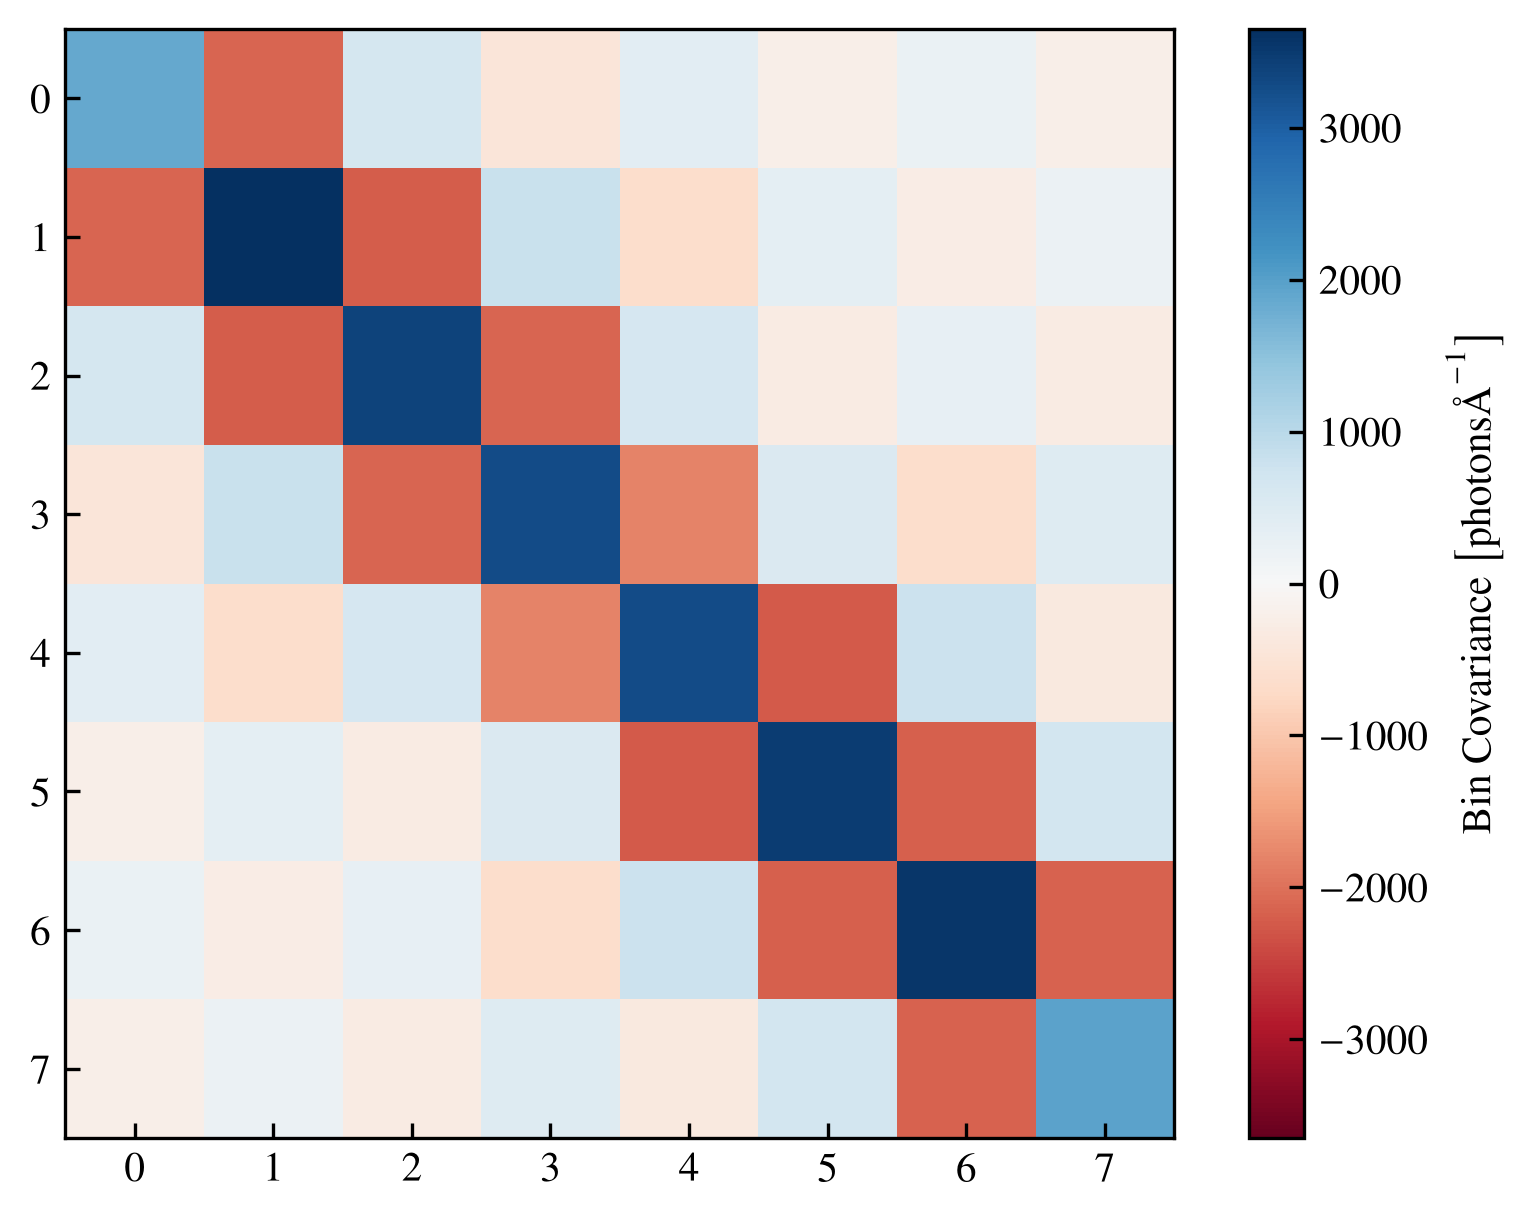

In [ ]:
v = np.max(np.abs(coarse_cov_angstrom))

fig, ax = plt.subplots()

im = ax.imshow(
    coarse_cov_angstrom,
    vmin=-v,
    vmax=v,
    cmap='RdBu_r',
    origin='upper'
)

# inward-facing ticks
ax.tick_params(direction='in')

# colourbar
cbar = fig.colorbar(im, ax=ax)

# inward-facing colourbar ticks
cbar.ax.tick_params(direction='in')

# colourbar label
cbar.set_label(r'Bin Covariance $\big[ \mathrm{photons}  \text{\AA}^{-1} \big]$')


plt.show()

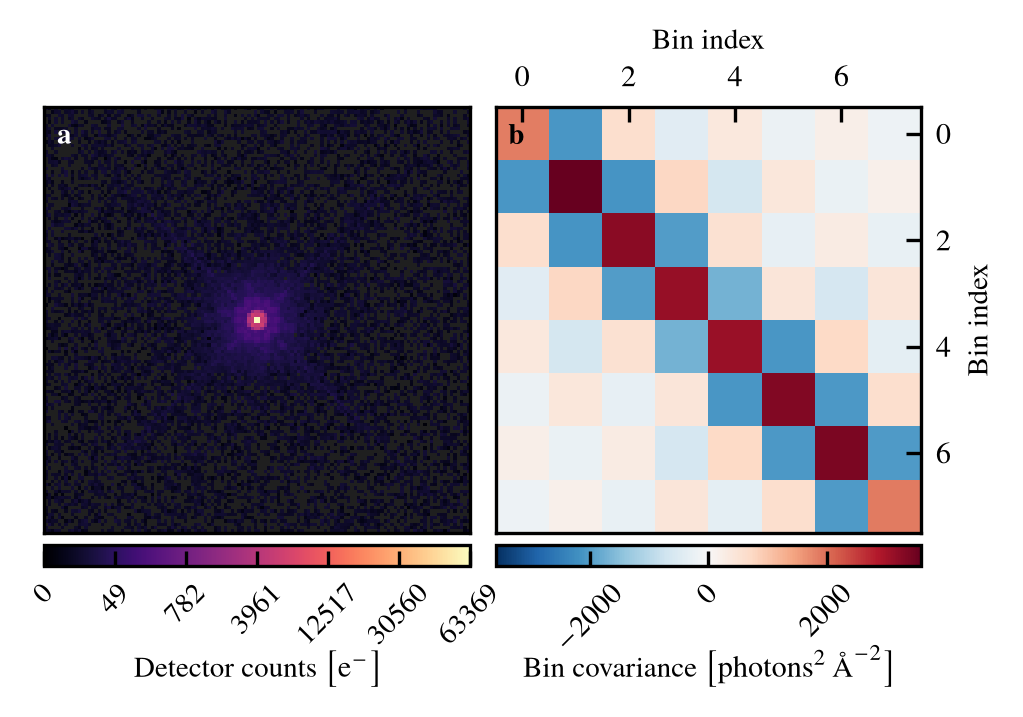

In [123]:
v = np.max(np.abs(coarse_cov_angstrom))

fig_width_single = 82.5 / 25.4
fig, (ax2, ax1) = plt.subplots(
    1, 2,
    figsize=(fig_width_single, 0.72*fig_width_single)
)

fig.subplots_adjust(
    left=0.02,
    right=0.92,
    bottom=0.12,
    top=0.98,
    wspace=0.06
)

# covariance matrix
im1 = ax1.imshow(
    coarse_cov_angstrom,
    vmin=-v,
    vmax=v,
    cmap='RdBu_r',
    origin='upper'
)

ax1.tick_params(direction='in')

# put x axis on top
ax1.xaxis.tick_top()
ax1.xaxis.set_label_position('top')
ax1.set_xlabel('Bin index')
ax1.set_ylabel('Bin index')
ax1.yaxis.tick_right()
ax1.yaxis.set_label_position('right')
ax1.set_yticks([0, 2, 4, 6])

# horizontal colourbar below
cbar1 = fig.colorbar(
    im1,
    ax=ax1,
    orientation='horizontal',
    pad=0.02
)

cbar1.ax.tick_params(direction='in', labelrotation=45)
cbar1.set_label(
    r'Bin covariance $\big[ \mathrm{photons}^2\,\text{\AA}^{-2} \big]$',
    labelpad=-3
)

# ## data image
# data_flattened = np.sign(data) * np.abs(data)**0.25

# v = np.max(np.abs(data_flattened))

# im2 = ax2.imshow(
#     data_flattened,
#     vmin=-v,
#     vmax=v,
#     cmap='berlin_r',
#     origin='lower'
# )
# ax2.set_yticks([])
# ax2.set_xticks([])

# # Ticks equally spaced in ORIGINAL data
# ticks = np.linspace(np.min(data), np.max(data), 7)
# ticks = np.array([0,1000, 5000, 10000, 20000, 40000, 60000])

# # Their positions in the transformed colour space
# tick_positions = np.sign(ticks) * np.abs(ticks)**0.25
# tick_positions = np.linspace(0, 60000**0.25, 7)
# # cbar.set_ticks(tick_positions)
# # cbar.set_ticklabels([f'{x:.0f}' for x in ticks])
# # cbar.set_ticklabels([r'$0$', r'$20 \times 10^3$', r'$40 \times 10^3$', r'$60 \times 10^3$'])
# # cbar.ax.tick_params(direction='in')
# # cbar.set_label('Photons')

# cbar = fig.colorbar(
#     im2,
#     ax=ax2,
#     orientation='horizontal',
#     pad=0.02
# )

# cbar.ax.set_xlim(
#     np.min(data_flattened),
#     np.max(data_flattened)
# )

# cbar.set_ticks(tick_positions)
# # cbar.set_ticklabels([
# #     r'$0$',
# #     r'$5000$',
# #     r'$10000$',
# #     r'$20000$',
# #     r'$40000$',
# #     r'$60000$'
# # ])
# cbar.set_ticklabels([
#     f'{tick**4:.0f}' for tick in tick_positions
# ])

## data image
gamma = 0.25

data_nonnegative = np.where(data < 0, np.nan, data)
data_flattened = data_nonnegative**gamma
v = float(np.nanmax(data_flattened))

cmap = plt.get_cmap("magma").copy()
cmap.set_bad("0.125")

im2 = ax2.imshow(
    data_flattened,
    vmin=0,
    vmax=v,
    cmap=cmap,
    origin="lower",
)
ax2.set_yticks([])
ax2.set_xticks([])

cbar = fig.colorbar(
    im2,
    ax=ax2,
    orientation="horizontal",
    pad=0.02,
)

# Evenly spaced in displayed colour, labelled in original counts.
tick_positions = np.linspace(0, v, 7)
cbar.set_ticks(tick_positions)
cbar.set_ticklabels([
    f"{tick**(1 / gamma):.0f}" for tick in tick_positions
])

cbar.ax.tick_params(direction='in', labelrotation=45)
cbar.set_label(r'Detector counts $\big[ \mathrm{e}^{-} \big]$',
               labelpad=0.0)
# # image spines
# for spine in ax2.spines.values():
#     spine.set_color('0.5')

# # colourbar outline
# cbar.outline.set_edgecolor('0.5')

# colourbar ticks + tick labels
cbar.ax.tick_params(
    direction='in',
    # colors='0.5',
    # labelcolor='0.5'
)

# colourbar label too, if desired
# cbar.ax.xaxis.label.set_color('0.5')
ax2.text(
    0.03, 0.96,
    r'\textbf{a}',
    transform=ax2.transAxes,
    ha='left',
    va='top',
    color='white'
)

ax1.text(
    0.03, 0.96,
    r'\textbf{b}',
    transform=ax1.transAxes,
    ha='left',
    va='top',
    color='k'
)

plt.savefig('image_bins_newsize.pdf', dpi=300, backend='pgf')
plt.show()

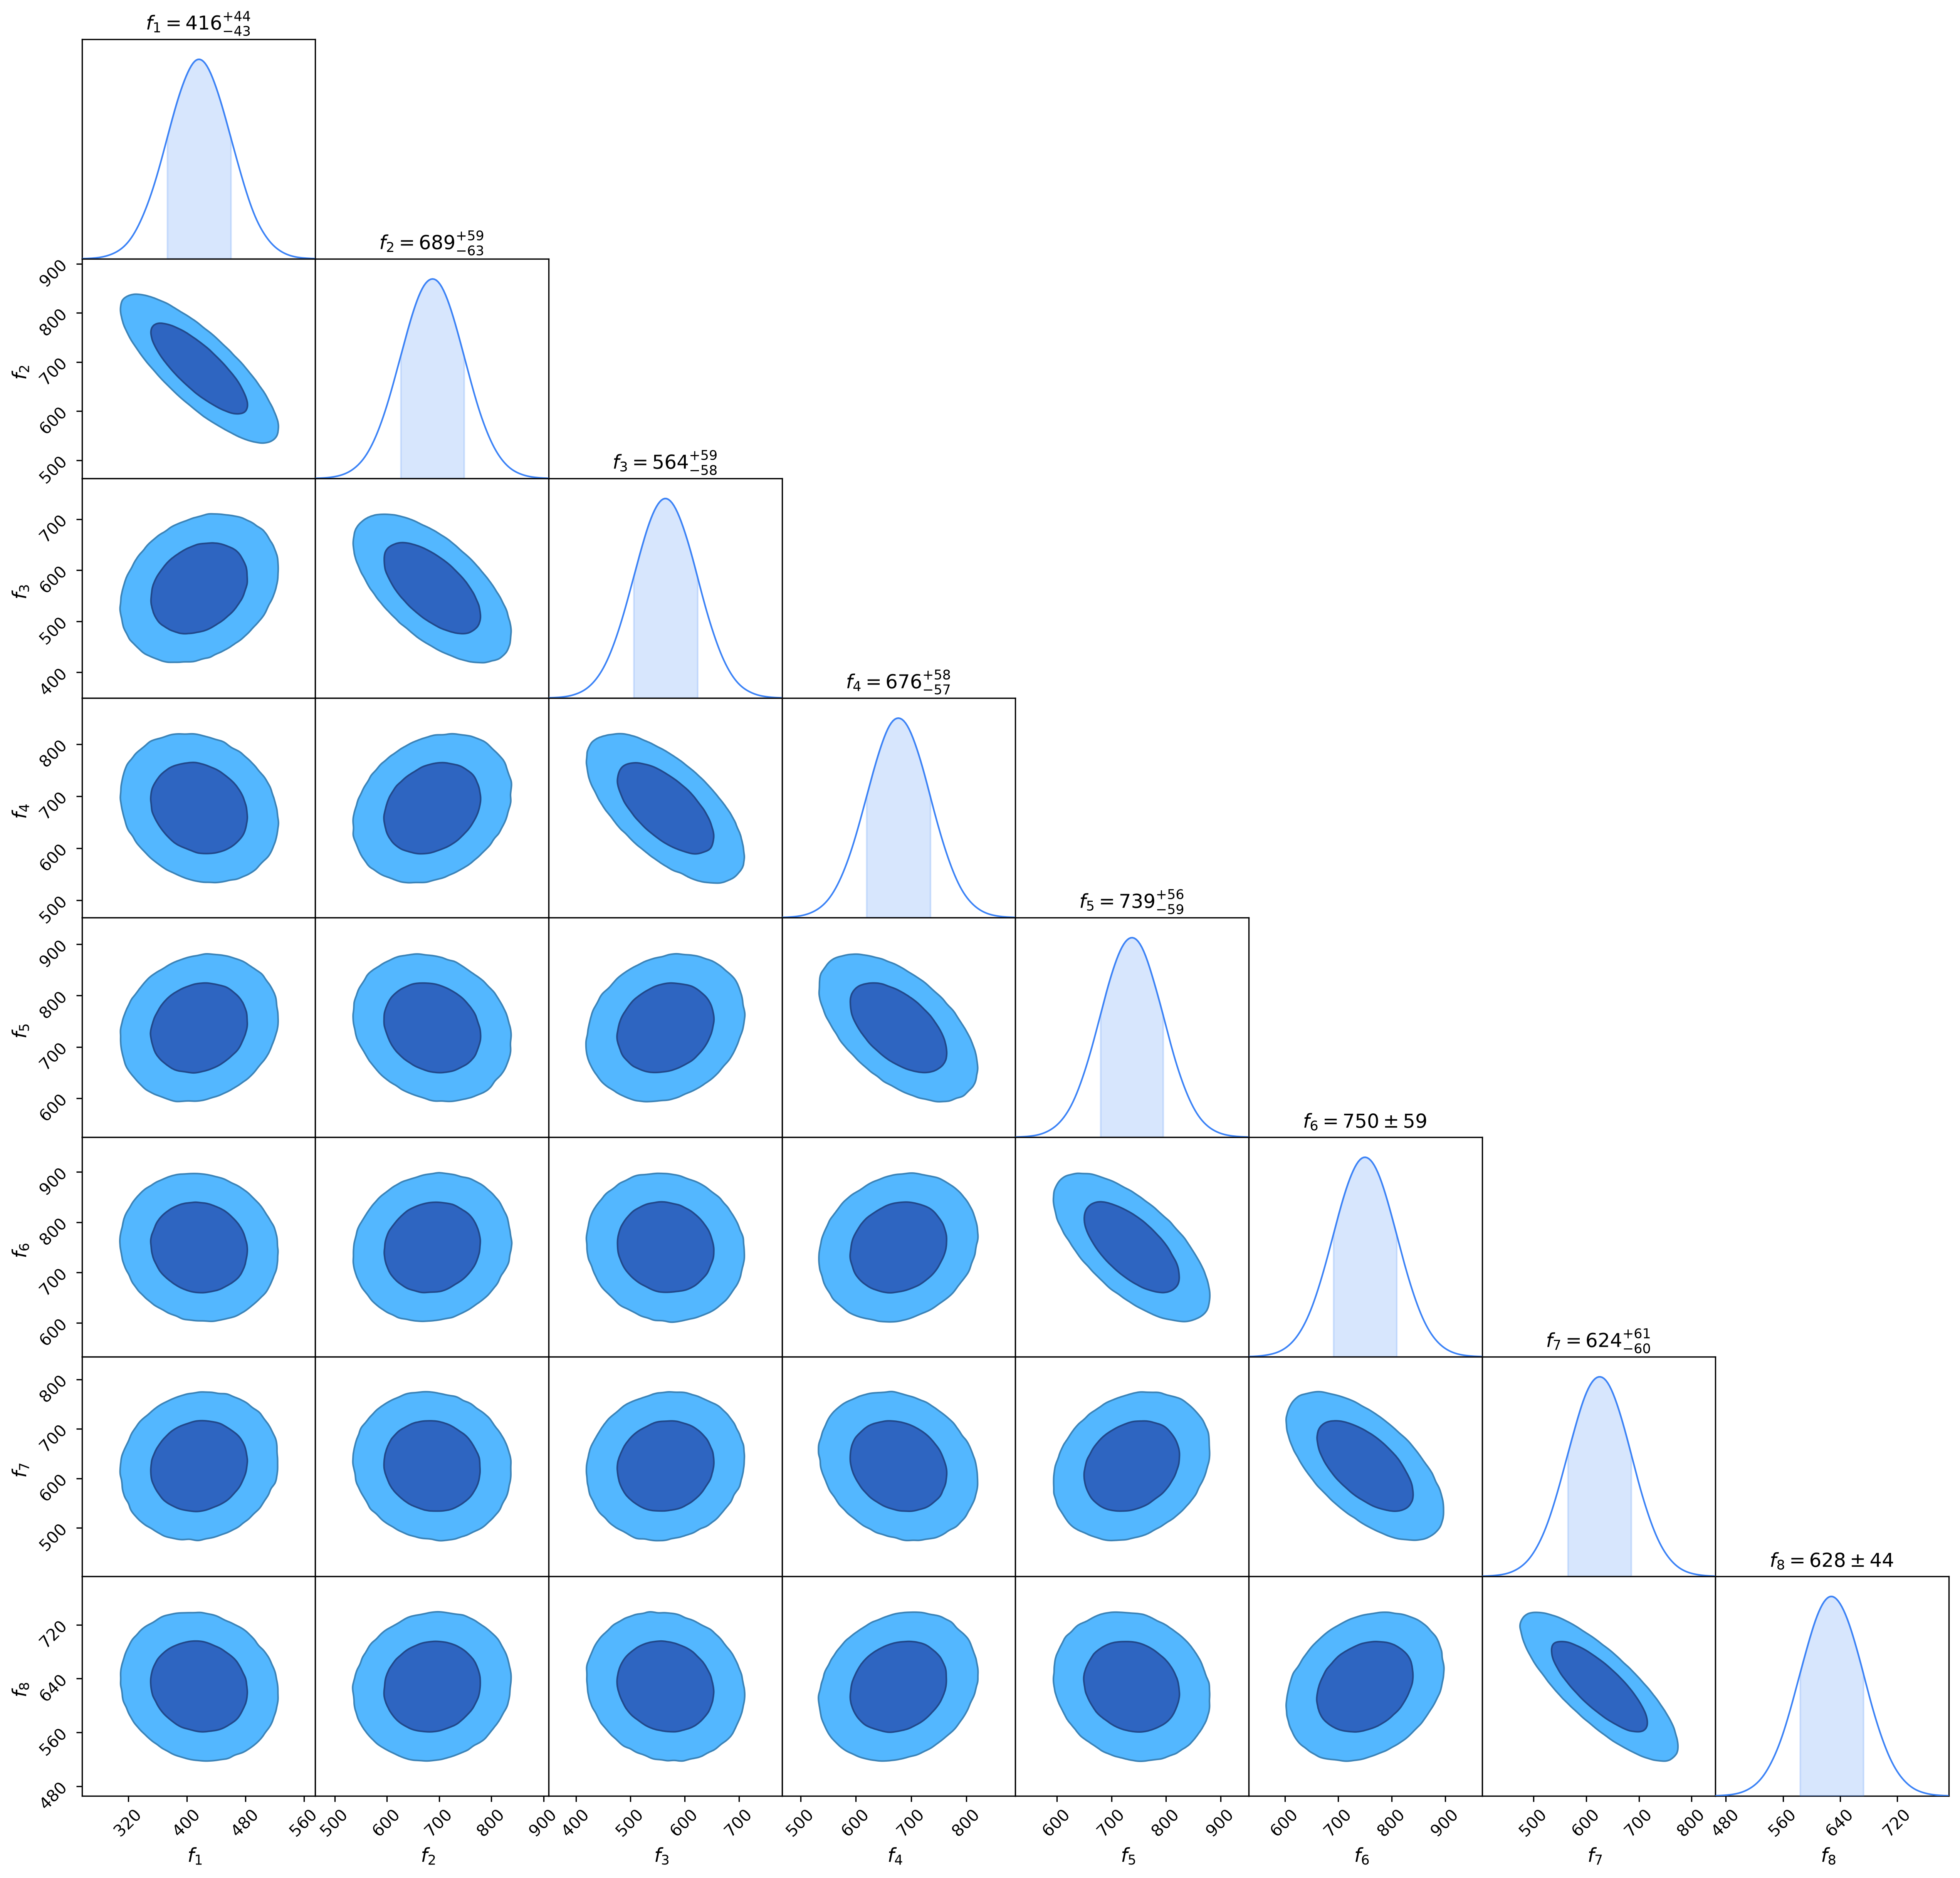

In [51]:
from chainconsumer import Chain, ChainConsumer

# Mean recovered flux density in each bin
mean = bin_recov_flux_angstrom

# Covariance of the binned flux densities
cov = coarse_cov_angstrom

# Names for each spectral bin
columns = [
    rf"$f_{{{i+1}}}$"
    for i in range(n_bins)
]

chain = Chain.from_covariance(
    mean=mean,
    covariance=cov,
    columns=columns,
    name="Recovered spectrum",
)

c = ChainConsumer()
c.add_chain(chain)

fig = c.plotter.plot()

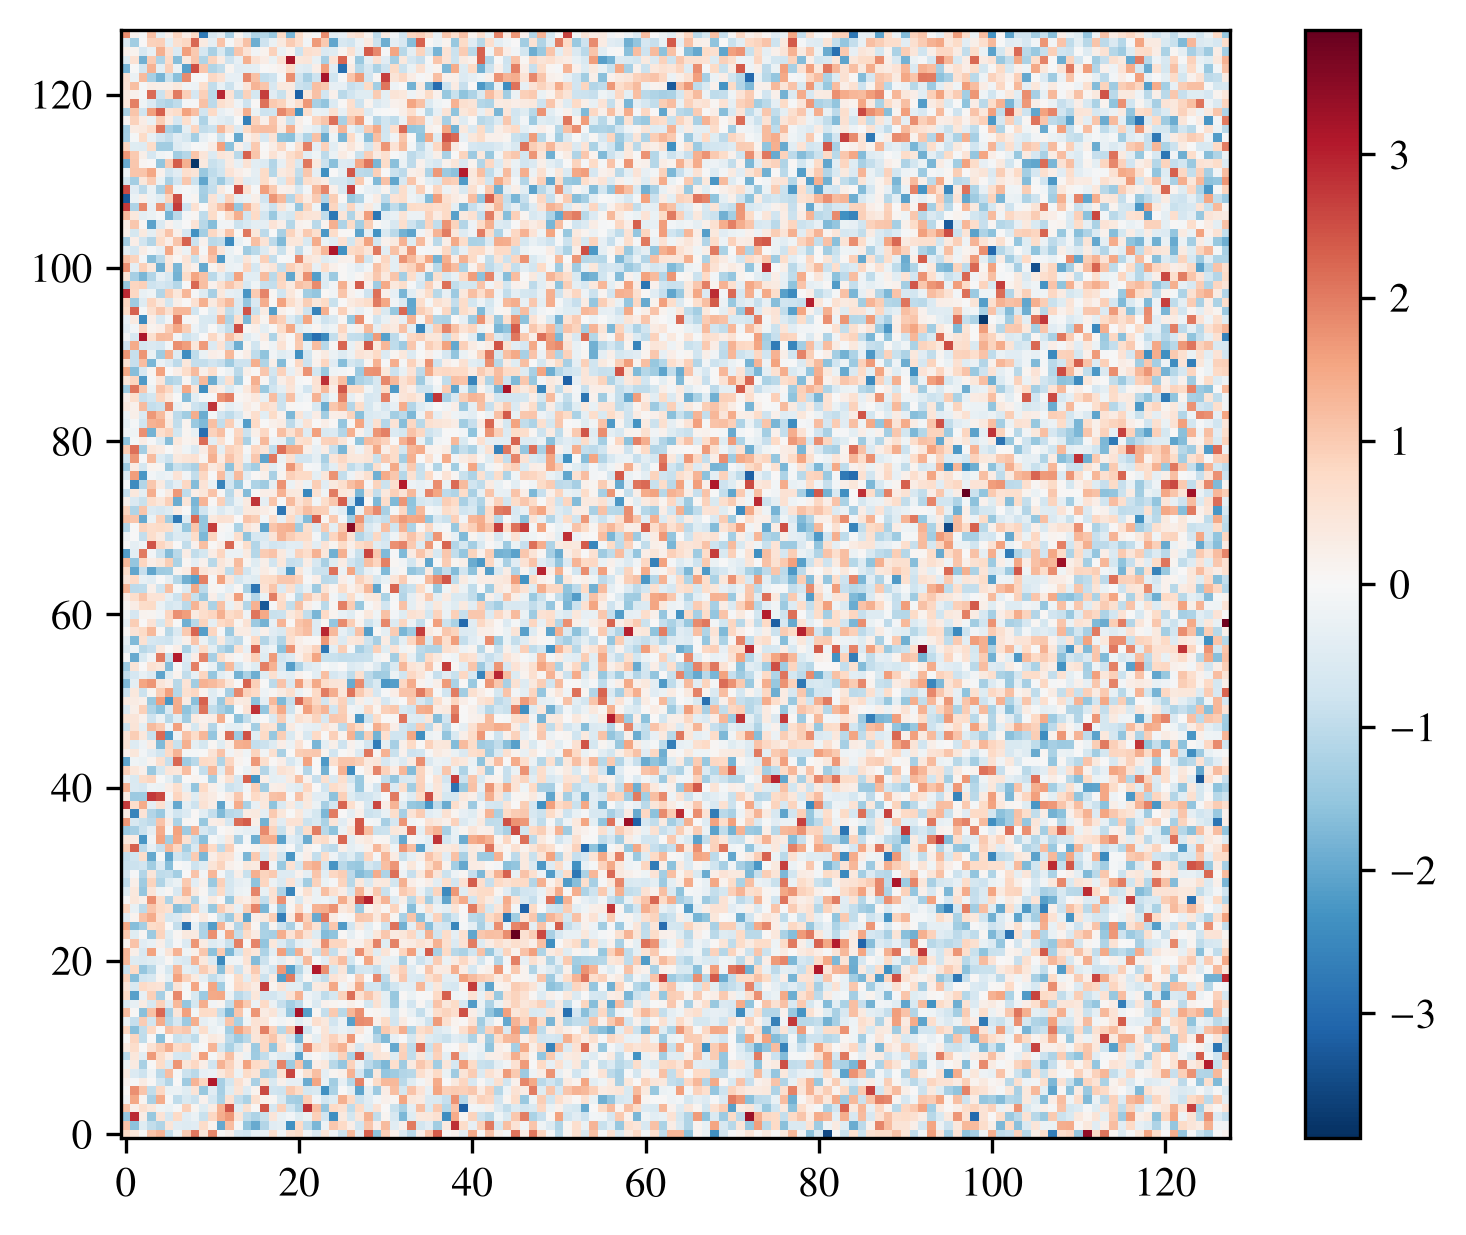

In [713]:
# data - model
img_final = model_psf(spec_mean, instrument)
img_residual = (data - img_final)/np.sqrt(img_final + read_noise**2)
v_res = np.max(np.abs(img_residual))
plt.imshow(img_residual, vmin=-v_res, vmax=v_res, cmap='RdBu_r')
plt.colorbar()
plt.show()

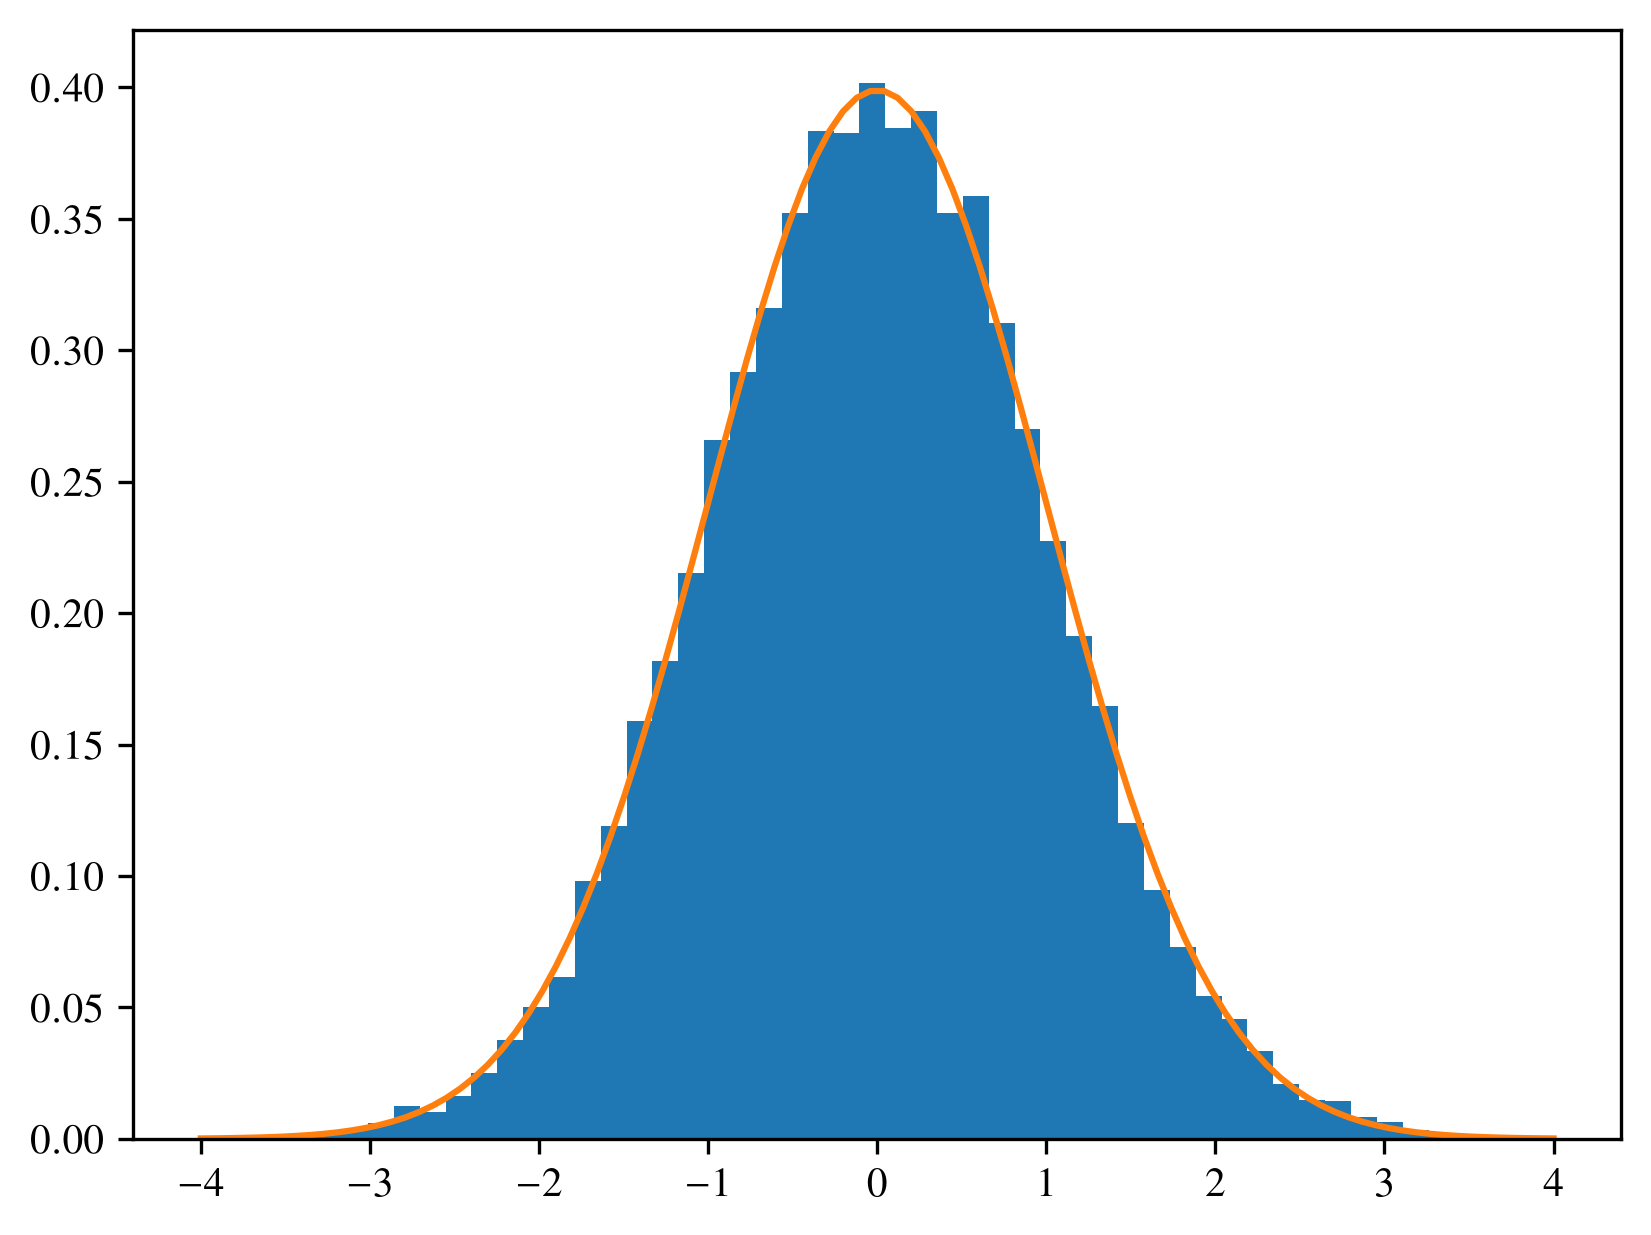

In [724]:
plt.hist(img_residual.flatten(), bins=50, density=True)
zs = np.linspace(-4,4,100)
import scipy.stats as stats
plt.plot(zs, stats.norm.pdf(zs, 0 ,1))
plt.show()
# frick yes

In [721]:
img_residual.flatten()

Array([ 0.75399862,  0.43599865,  0.04013782, ..., -0.22652943,
        0.77714801, -1.47725252], dtype=float64)

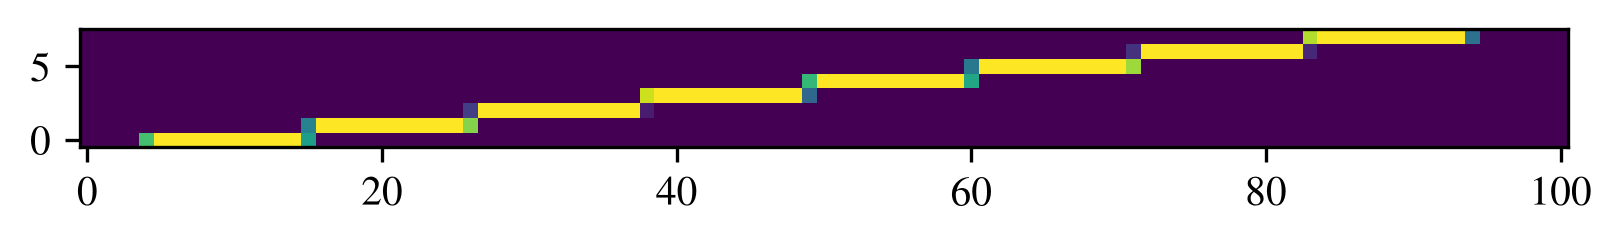

In [88]:
plt.imshow(B)

In [ ]:
## i'm going a bit crazy. no need to deal with the intermediate product

In [ ]:
print()